<a href="https://colab.research.google.com/github/SakshamPainuly/underwater-creature-tracking/blob/anu%2Fmodel-development/my_model/colab_train_rtdetr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UWCT — Colab RT-DETR training (E005, YOLO vs RT-DETR comparison)

Same pipeline as `notebooks/colab_train_baseline.ipynb` (YOLO E001), run for **E005**:
`rtdetr-l.pt` with **AMP off** (D-025). E005 replaces E003 (D-015), whose full run diverged to NaN
losses with AMP on. Runbook: `docs/COLAB.md`. This notebook only calls repository scripts.

- Runtime: **GPU** (Runtime → Change runtime type). Never run training on the local PC.
- Same frozen dataset **v1** view as E001 (YOLO-format labels, no conversion needed);
  zExtra never reaches training; the training data file has **no test split**.
- `train_yolo.py` detects the RT-DETR checkpoint and uses Ultralytics' `RTDETR` class.
- Runs, checkpoints and records go to `MyDrive/uwct/runs/E005*/` (outside Git). Never resume `E003/`.
- Before the full run: the smoke test (cell 12) must finish **without NaN losses** and within GPU
  memory at batch 16 in fp32. If not, stop — changing batch or lr needs a new decision (D-025).
- The **FINAL TEST EVALUATION** section runs only after E005 is registered, reviewed and declared
  in `experiments/final_candidates.csv`.

In [1]:
# 1. Settings -- set COMMIT (full 40-character sha of the commit to run); keep everything else.
import os, re, subprocess, sys

REPO = "SakshamPainuly/underwater-creature-tracking"
BRANCH = "anu/model-development"
COMMIT = "a2b9f9935e06ef4a4ac3681dfb84cfe3d4ec9b4a"  # REQUIRED: `git rev-parse HEAD` on the local PC, after that commit is pushed
# E005 trained at 292d9ab4f16de6220acade25c2718a6d30d793ce (100 epochs, run_record.json finalized on Drive
# 2026-10-15). --resume/finalize only accept that commit; the COMMIT above (which declares E005 in
# experiments/final_candidates.csv and holds the D-027 final_test.py) is for the FINAL TEST EVALUATION
# section only.
EXPERIMENT_CONFIG = "configs/experiments/E005_rtdetr_amp_off.yaml"
EXPERIMENT_ID = "E005"
TOKEN_SECRET_NAME = "UWCT_GITHUB_TOKEN"  # Colab Secrets: fine-grained, this repo only, Contents read-only

REPO_DIR = "/content/uwct"                             # fixed: resumed runs expect the same dataset path
DRIVE_RAW = "/content/drive/MyDrive/uwct/raw/biology"  # Set 100 + Set 2000 only (no zExtra)
RUNS_ROOT = "/content/drive/MyDrive/uwct/runs"         # persistent run folders
LOCAL_RAW = "/content/raw/biology"                     # fast local copy used for training
WEIGHTS_DIR = "/content/weights"                       # pretrained checkpoints downloaded by Ultralytics

assert re.fullmatch(r"[0-9a-f]{40}", COMMIT), "Set COMMIT to the exact 40-character commit sha to run"


def sh(*cmd):
    """Run a command in the repo, stream its output, raise if it fails."""
    p = subprocess.Popen(list(cmd), cwd=REPO_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"FAILED (exit {p.returncode}): {' '.join(cmd)}")


# Ultralytics prints a progress-bar line for every batch (~190 lines per epoch); thousands of lines
# freeze the Colab browser tab. Training cells use sh_train: the full output goes to a log file on
# Drive, the cell shows only finished-epoch lines, validation results, warnings and errors.
_PROGRESS = re.compile(r"\b\d{1,2}% [━─╸ ]")  # an unfinished progress bar (0-99%)
_REPEATED = ("grid_sampler_2d_backward_cuda", "_execution_engine.run_backward")


def sh_train(*cmd):
    """Like sh(), with a short cell output and the full output in RUNS_ROOT/<id>_logs/<utc>.log."""
    from datetime import datetime, timezone
    log_dir = os.path.join(RUNS_ROOT, EXPERIMENT_ID + "_logs")  # not inside the run folder
    os.makedirs(log_dir, exist_ok=True)
    log_path = os.path.join(log_dir, datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + ".log")
    print("full log:", log_path)
    shown = set()
    with open(log_path, "w", encoding="utf-8", buffering=1) as log:
        p = subprocess.Popen(list(cmd), cwd=REPO_DIR, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
        for line in p.stdout:
            log.write(line)
            if _PROGRESS.search(line):
                continue
            if any(k in line for k in _REPEATED):
                if line in shown:
                    continue
                shown.add(line)
            print(line, end="")
    if p.wait() != 0:
        raise RuntimeError(f"FAILED (exit {p.returncode}): {' '.join(cmd)} -- see {log_path}")

In [2]:
# 2. GPU present? Training never runs on CPU (CLAUDE.md rule 3).
import shutil
assert shutil.which("nvidia-smi"), (
    "NO GPU in this runtime. Runtime -> Change runtime type -> T4 GPU -> Save, then run cells from 1 again. "
    "If no GPU is offered, the Colab GPU quota is used up: try again later; do not train on CPU.")
print(subprocess.run(["nvidia-smi"], capture_output=True, text=True).stdout)

Sun Oct 18 23:58:31 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [3]:
# 3. Mount Google Drive (raw training subset + persistent runs folder)
from google.colab import drive
drive.mount("/content/drive")
os.makedirs(RUNS_ROOT, exist_ok=True)

Mounted at /content/drive


In [4]:

# 4. Check out the exact commit (read-only token from Colab Secrets; see docs/COLAB.md).
# Git obtains credentials through GIT_ASKPASS.
# The token is not placed in the Git URL, command-line arguments, or helper file.

import os
import stat
import subprocess
from google.colab import userdata

REPO_URL = f"https://github.com/{REPO}.git"
ASKPASS = "/content/uwct_git_askpass.sh"

with open(ASKPASS, "w") as f:
    f.write(
        '#!/bin/sh\n'
        'case "$1" in\n'
        '  Username*) echo "x-access-token" ;;\n'
        '  *) printf "%s\\n" "$UWCT_GIT_TOKEN" ;;\n'
        'esac\n'
    )

os.chmod(ASKPASS, stat.S_IRWXU)


def git(*args, cwd=REPO_DIR):
    """Local Git commands; no credentials involved."""
    r = subprocess.run(
        ["git", *args],
        cwd=cwd,
        capture_output=True,
        text=True
    )
    if r.returncode != 0:
        raise RuntimeError(f"git {args[0]} failed:\n{r.stderr}")
    return r.stdout.strip()


def git_remote(*args, cwd=REPO_DIR):
    """Run clone/fetch with the Colab Secret available to this Git process."""

    # Use the exact name of your Colab Secret.
    token = userdata.get("uwct_token")

    if not token:
        raise RuntimeError(
            'Colab Secret "uwct_token" is missing, empty, '
            "or notebook access is disabled."
        )

    env = {
        **os.environ,
        "GIT_ASKPASS": ASKPASS,
        "GIT_TERMINAL_PROMPT": "0",
        "UWCT_GIT_TOKEN": token,
    }

    try:
        r = subprocess.run(
            ["git", "-c", "credential.helper=", *args],
            cwd=cwd,
            env=env,
            capture_output=True,
            text=True
        )

        err = r.stderr.replace(token, "***")

        config = os.path.join(REPO_DIR, ".git", "config")
        leaked = (
            os.path.isfile(config)
            and token in open(config, encoding="utf-8").read()
        )

    finally:
        env.pop("UWCT_GIT_TOKEN", None)
        token = None

    if r.returncode != 0:
        if "403" in err or "not granted" in err:
            err += (
                '\nThe token in Colab Secret "uwct_token" may not have '
                f"read access to repository {REPO}. Check the token's "
                "resource owner, repository access, and Contents: Read-only "
                "permission. See docs/COLAB.md, 'One-time setup'."
            )

        raise RuntimeError(f"git {args[0]} failed:\n{err}")

    assert not leaked, "Token found in .git/config"


# Clone the repository or fetch the requested branch.
if not os.path.isdir(REPO_DIR):
    git_remote(
        "clone",
        "--branch", BRANCH,
        REPO_URL,
        REPO_DIR,
        cwd="/content"
    )
else:
    git_remote("fetch", "origin", BRANCH)

# Check out and verify the exact commit.
git("checkout", "--detach", COMMIT)

assert git("rev-parse", "HEAD") == COMMIT
assert git("remote", "get-url", "origin") == REPO_URL

print(
    "commit:", COMMIT,
    "| working tree:", git("status", "--porcelain") or "clean"
)


commit: a2b9f9935e06ef4a4ac3681dfb84cfe3d4ec9b4a | working tree: clean


In [5]:
# 5. Install the pinned GPU requirements (ultralytics==8.4.155; torch/CUDA come from Colab)
sh(sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-gpu.txt")
sh(sys.executable, "-c", "import ultralytics, torch; print('ultralytics', ultralytics.__version__, "
   "'| torch', torch.__version__, '| cuda', torch.version.cuda)")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.5/46.5 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 29.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.6/97.6 kB 8.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
ultralytics 8.4.155 | torch 2.11.0+cu130 | cuda 13.0


In [6]:
# 6. Environment report for this session (each run record stores its own copy too)
sh(sys.executable, "scripts/env_report.py", "--out", "/content/env_report_session.json")

{
  "timestamp_utc": "2026-10-18T23:59:06+00:00",
  "os": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "python": "3.13.15",
  "cpu_count": 2,
  "torch": "2.11.0+cu130",
  "cuda_available": true,
  "cuda_version": "13.0",
  "cudnn_version": 92700,
  "gpus": [
    {
      "index": 0,
      "name": "Tesla T4",
      "vram_gb": 14.56
    }
  ],
  "ultralytics": "8.4.155",
  "nvidia_smi": [
    {
      "name": "Tesla T4",
      "memory_total": "15360 MiB",
      "driver_version": "580.82.07"
    }
  ]
}


In [7]:
# 7. Reconstruct Biology raw data locally from the shared ZIP.
#    Nothing is written back to Google Drive.

import os
import shutil
import zipfile
import subprocess
import sys
from pathlib import Path

ZIP_ID = "1_97E8IGX_euJLAzXlyfpukhvRjg2XhfM"
ZIP_PATH = Path("/content/biology_dataset.zip")
LOCAL_RAW = Path("/content/raw/biology")

# Install gdown
subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "gdown"],
    check=True
)

# Download shared ZIP. gdown prints its own reason above any error raised here.
EXPECTED_ZIP_BYTES = 5_478_326_324  # size of the shared ZIP as downloaded on 2026-10-14 (OBSERVED)
print("Downloading Biology ZIP...")
dl = subprocess.run(
    [
        sys.executable,
        "-m",
        "gdown",
        f"https://drive.google.com/uc?id={ZIP_ID}",
        "-O",
        str(ZIP_PATH),
    ]
)
if dl.returncode != 0 or not ZIP_PATH.is_file():
    raise RuntimeError(
        f"gdown could not download Drive file {ZIP_ID} (exit {dl.returncode}); its message is printed above.\n"
        "Common causes:\n"
        "  - 'Too many users have viewed or downloaded this file recently': Drive's download quota; try again later.\n"
        "  - 'Cannot retrieve the public link' / access denied: the file is no longer shared as "
        "'Anyone with the link', or it was moved or deleted. The file's owner has to check this.\n"
        "Upgrading gdown fixes neither. /content/raw/biology has not been touched."
    )

size = ZIP_PATH.stat().st_size
print("Downloaded:", ZIP_PATH)
print("Size:", size, "bytes")
if size != EXPECTED_ZIP_BYTES or not zipfile.is_zipfile(ZIP_PATH):
    raise RuntimeError(
        f"{ZIP_PATH} is {size} bytes (expected {EXPECTED_ZIP_BYTES}) or is not a valid ZIP: an incomplete "
        "download or a Drive error page. Run this cell again. If the size is stable but different, the shared "
        "ZIP itself has changed: stop and check with the data owner before using it."
    )

# Start clean -- only after the download is complete and valid
if LOCAL_RAW.exists():
    shutil.rmtree(LOCAL_RAW)

LOCAL_RAW.mkdir(parents=True, exist_ok=True)

# Extract outer ZIP
OUTER = Path("/content/biology_outer")
if OUTER.exists():
    shutil.rmtree(OUTER)
OUTER.mkdir()

print("\nExtracting outer ZIP...")
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(OUTER)

ROOT = OUTER / "AI Lobster Training Dataset"

# Set 100
print("\nCopying Set 100...")
shutil.copytree(
    ROOT / "Set 100",
    LOCAL_RAW / "Set 100"
)

# Set 2000 images
IMG_ZIP = ROOT / "Set 2000" / "batch_2 (2k - imgOnly).zip"
IMG_DST = LOCAL_RAW / "Set 2000" / "batch_2 (2k - imgOnly)"

print("Extracting Set 2000 images...")
IMG_DST.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(IMG_ZIP, "r") as z:
    z.extractall(IMG_DST)

# Set 2000 labels
LABEL_ZIP = ROOT / "Set 2000" / "batch_2_2k_labels.zip"
LABEL_DST = LOCAL_RAW / "Set 2000" / "batch_2_2k_labels"

print("Extracting Set 2000 labels...")
LABEL_DST.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(LABEL_ZIP, "r") as z:
    z.extractall(LABEL_DST)

# zExtra stays in raw data for fingerprint verification,
# but remains excluded from the frozen training view.
print("Copying zExtra Photos...")
shutil.copytree(
    ROOT / "zExtra Photos",
    LOCAL_RAW / "zExtra Photos"
)

# Project documents
for name in [
    "Lobster AI Detection Training Data.docx",
    "What's been done.xlsx",
]:
    src = ROOT / name
    if src.exists():
        shutil.copy2(src, LOCAL_RAW / name)

# Tell all subsequent project scripts where raw data lives
os.environ["UWCT_RAW_ROOT"] = str(LOCAL_RAW)

print("\n=== RAW ROOT ===")
print(LOCAL_RAW)

print("\n=== TOP LEVEL ===")
for p in sorted(LOCAL_RAW.iterdir()):
    print(p.name)

assert (LOCAL_RAW / "Set 100").is_dir()
assert (LOCAL_RAW / "Set 2000").is_dir()
assert (LOCAL_RAW / "zExtra Photos").is_dir()

print("\nCell 7 reconstruction complete.")

Downloaded: /content/biology_dataset.zip
Size: 5478326324 bytes

Extracting outer ZIP...

Copying Set 100...
Extracting Set 2000 images...
Extracting Set 2000 labels...
Copying zExtra Photos...

=== RAW ROOT ===
/content/raw/biology

=== TOP LEVEL ===
Set 100
Set 2000
What's been done.xlsx
zExtra Photos

Cell 7 reconstruction complete.


In [8]:
# 8. Raw-data check of the local copy (structural: paths + sizes; txt contents hashed). Must MATCH.
sh(sys.executable, "scripts/check_raw_unchanged.py", "--root", LOCAL_RAW, "--subset", "training")

check: structural (paths+sizes; txt/xlsx/docx hashed); subset: training; root: /content/raw/biology
fingerprint: /content/uwct/data/processed/raw_fingerprint_d011_post_cleanup.json
files expected: 3969  present: 3969
  missing: 0
  added: 0
  size changed: 0
  content changed: 0
RAW DATA MATCHES FINGERPRINT


In [9]:
# 9. Build the YOLO view of frozen v1 (verifies FROZEN.json hashes first; symlinks to the local copy)
sh(sys.executable, "scripts/prepare_yolo_dataset.py", "--version", "v1")

raw data root: /content/raw/biology
{
  "dataset_name": "lobster_v1",
  "dataset_version": "v1",
  "version_status": "frozen",
  "dataset_fingerprint": "9f2bf8573df4354e1373786967a1155802e4cdbfe127e1f07fd3fdb1983ef810",
  "inputs": {
    "image_manifest_sha256": "368bdfa0d127480d119c81047fb155ed80e39da392d15b92edc169b1c7ab9e0d",
    "split_manifest_sha256": "fccb4050e4fcdc25d5647d7b6fc7e59662b75e41000f525769a3eb95fac6aa71"
  },
  "git": {
    "commit": "a2b9f9935e06ef4a4ac3681dfb84cfe3d4ec9b4a",
    "dirty": false
  },
  "class_names": {
    "0": "lobster"
  },
  "target_ultralytics_version": "8.4.155",
  "link_mode": "symlink",
  "splits": {
    "train": {
      "images": 1433,
      "positive": 1274,
      "instances": 4000,
      "negative": 159
    },
    "val": {
      "images": 324,
      "negative": 55,
      "instances": 1010,
      "positive": 269
    },
    "test": {
      "images": 348,
      "positive": 321,
      "instances": 1512,
      "negative": 27
    }
  },
  "not_in

In [10]:
# 10. Ultralytics reads the view exactly as built. Must print VERIFIED.
sh(sys.executable, "scripts/verify_yolo_dataset.py", "--dataset", "data/yolo/lobster_v1")


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 192.6±166.1 MB/s, size: 1511.5 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 4 images, 4 backgrounds, 0 corrupt: 0% ──────────── 4/1433 11.7it/s 0.1s<2:02
val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 11 images, 11 backgrounds, 0 corrupt: 0% ──────────── 11/1433 28.7it/s 0.2s<49.5s
val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 18 images, 17 backgrounds, 0 corrupt: 1% ──────────── 18/1433 38.6it/s 0.3s<36.7s
val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 26 images, 23 backgrounds, 0 corrupt: 1% ──────────── 26/1433 50.1it/s 0.4s<28.1s
val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 33 images, 30 backgrounds, 0 corrupt: 2% ──────────── 33/1433 56.0it/s 0.5s<25.0s
val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train... 39 images, 33 backgrounds, 0 corrupt: 2% ──────────── 39/1433 57.1it/s 0.6s<24.4s
val: Scanning /content/uwct/data/yo

In [11]:
# commit check
import subprocess

print("Current commit:")
print(
    subprocess.check_output(
        ["git", "rev-parse", "HEAD"],
        cwd="/content/uwct",
        text=True
    ).strip()
)

print("\nCandidate declaration:")
print(
    open(
        "/content/uwct/experiments/final_candidates.csv",
        encoding="utf-8"
    ).read()
)

Current commit:
a2b9f9935e06ef4a4ac3681dfb84cfe3d4ec9b4a

Candidate declaration:
experiment_id,declared_utc,decision,reason
E001,2026-09-19T19:50:42Z,candidate,"E001 baseline selected for held-out final evaluation after completed validation run"
E005,2026-10-15T01:35:54Z,candidate,"E005 RT-DETR-L (AMP off, batch 8; D-025, D-026) declared as final candidate while its full run is still training; evaluated on test only after the run is registered and reviewed"



In [ ]:
# 11. Preflight: every training check + load (download) the exact pretrained checkpoint.
#     If rtdetr-l.pt is unavailable in ultralytics 8.4.155 this STOPS -- report it; do not change the model.
TRAIN = [sys.executable, "scripts/train_yolo.py", "--config", EXPERIMENT_CONFIG,
         "--runs-root", RUNS_ROOT, "--weights-dir", WEIGHTS_DIR]
sh(*TRAIN, "--preflight-only")

val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 897.9±658.1 MB/s, size: 2033.3 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train.cache... 1433 images, 159 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1433/1433 240.4Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3297.0±1428.4 MB/s, size: 2099.5 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/val.cache... 324 images, 55 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 324/324 71.5Mit/s 0.0s
{
  "kind": "full",
  "created_utc": "2026-10-14T16:10:08+00:00",
  "run_name": "E005_preflight",
  "experiment": {
    "id": "E005",
    "slug": "rtdetr_amp_off",
    "parent": "E001",
    "changed": "model yolo26s.pt -> rtdetr-l.pt (as E003); amp true -> false (E003 diverged with AMP, D-025)",
    "config_path": "configs/experiments/E005_rtdetr_amp_off.yaml",
    "config_sha256": "b09760907a7020b12d54f2c5b3d7574cb43c55c607b08061562a32bfb1bfe8c6",
    "config": {
      "id": "E005",
      "slug": "rtdetr_amp_off",


In [ ]:
# 12. Smoke test: 1 epoch on 10% of train, validated on val -> RUNS_ROOT/E005_smoke_<utc>/
RUN_SMOKE = False  # set to True deliberately
assert RUN_SMOKE, "Smoke test not enabled"
sh_train(*TRAIN, "--smoke")

full log: /content/drive/MyDrive/uwct/runs/E005_logs/20261014T161038Z.log
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1784.2±175.4 MB/s, size: 2349.6 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/train.cache... 1433 images, 159 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1433/1433 316.3Mit/s 0.0s
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3628.0±1129.2 MB/s, size: 2309.3 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/val.cache... 324 images, 55 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 324/324 90.6Mit/s 0.0s
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=No

In [ ]:
# 12b. Smoke-test check (RT-DETR): losses must be finite before any full run (Ultralytics notes
#      AMP can give NaN for RT-DETR). Reads the newest smoke run's results.csv on Drive.
import csv, glob, math

smoke_dirs = sorted(glob.glob(os.path.join(RUNS_ROOT, EXPERIMENT_ID + "_smoke_*")))
assert smoke_dirs, "no smoke run found -- run cell 12 first"
with open(os.path.join(smoke_dirs[-1], "train", "results.csv"), newline="", encoding="utf-8") as f:
    rows = list(csv.DictReader(f))
last = {k.strip(): v for k, v in rows[-1].items()}
print(smoke_dirs[-1])
for k, v in last.items():
    print(f"{k:>28}: {v}")
bad = [k for k, v in last.items() if "loss" in k and not math.isfinite(float(v))]
assert not bad, f"non-finite losses {bad}: STOP -- record a decision before changing batch/amp (D-025)"
print("Smoke losses are finite.")

/content/drive/MyDrive/uwct/runs/E005_smoke_20261014T161039
                       epoch: 1
                        time: 62.6811
             train/giou_loss: 1.91411
              train/cls_loss: 3.58464
               train/l1_loss: 1.13557
        metrics/precision(B): 0.00014
           metrics/recall(B): 0.01386
            metrics/mAP50(B): 0.00012
         metrics/mAP50-95(B): 2e-05
               val/giou_loss: 2.75856
                val/cls_loss: 0.09872
                 val/l1_loss: 2.00021
                      lr/pg0: 0.002
                      lr/pg1: 0.002
                      lr/pg2: 0.002
Smoke losses are finite.


In [ ]:
# 13. Full training run -> RUNS_ROOT/E005/. Only after the smoke test passed and the run is approved.
# RUN_FULL = True  # set to True deliberately
# assert RUN_FULL, "Full training not enabled"
# sh_train(*TRAIN)

full log: /content/drive/MyDrive/uwct/runs/E005_logs/20261014T161254Z.log
STOPPED: /content/drive/MyDrive/uwct/runs/E005 already exists; use --resume, or a new experiment id


RuntimeError: FAILED (exit 1): /usr/bin/python3 scripts/train_yolo.py --config configs/experiments/E005_rtdetr_amp_off.yaml --runs-root /content/drive/MyDrive/uwct/runs --weights-dir /content/weights -- see /content/drive/MyDrive/uwct/runs/E005_logs/20261014T161254Z.log

In [ ]:
# 13b. Checkpoint backups -- run before cell 14 in every session (cells 1-11 first).
#      Ultralytics keeps one last.pt and overwrites it every epoch; a run started from scratch in the same
#      folder replaced 54 E005 epochs on 2026-10-14. This copies last.pt to RUNS_ROOT/<id>_backups/ after
#      every epoch as epoch<NNN>.pt and keeps the 5 newest epochs plus every 10th (~264 MB each).
#      epoch000.pt is the final checkpoint Ultralytics writes when training ends. Runs in the background
#      until the runtime stops. To restore: copy a backup over RUNS_ROOT/<id>/train/weights/last.pt.
#      Ultralytics rewrites last.pt in place and every checkpoint has the same size, so a backup is kept only
#      if last.pt did not change while it was copied and the copy is a complete zip (CRC of every member).
import shutil, threading, time, zipfile
import torch

BACKUP_SRC = os.path.join(RUNS_ROOT, EXPERIMENT_ID, "train", "weights", "last.pt")
BACKUP_DIR = os.path.join(RUNS_ROOT, EXPERIMENT_ID + "_backups")  # not inside the run folder
os.makedirs(BACKUP_DIR, exist_ok=True)


def _version(path):
    st = os.stat(path)
    return st.st_mtime_ns, st.st_size


def _complete_zip(path):
    """torch checkpoints are zip files: a truncated or half-written copy fails here."""
    try:
        with zipfile.ZipFile(path) as z:
            return z.testzip() is None
    except (zipfile.BadZipFile, OSError):
        return False


def _backup_once(version, keep_newest=5, keep_every=10):
    """Copy last.pt if it is still at `version`; return False (nothing kept) if it changed or is incomplete."""
    tmp = os.path.join(BACKUP_DIR, "copying.tmp")
    try:
        shutil.copy2(BACKUP_SRC, tmp)
        if _version(BACKUP_SRC) != version or not _complete_zip(tmp):
            return False
        epoch = torch.load(tmp, map_location="cpu", weights_only=False).get("epoch", -1) + 1  # stored from 0
        os.replace(tmp, os.path.join(BACKUP_DIR, f"epoch{epoch:03d}.pt"))
    finally:
        if os.path.exists(tmp):
            os.remove(tmp)
    copies = sorted(f for f in os.listdir(BACKUP_DIR) if f.startswith("epoch") and f.endswith(".pt"))
    for f in copies[:-keep_newest]:
        if int(f[5:8]) % keep_every:
            os.remove(os.path.join(BACKUP_DIR, f))
    return True


def _backup_loop(every=60, settle=20, warn_after=3):
    seen, failures = None, 0
    while True:
        try:
            version = _version(BACKUP_SRC)
            if version != seen:
                time.sleep(settle)  # back up only a file that has stopped changing
                if _version(BACKUP_SRC) == version:
                    if _backup_once(version):
                        seen, failures = version, 0
                    else:
                        failures += 1
                        if failures == warn_after:
                            print(f"backup: last.pt kept changing or was incomplete {failures} times; still retrying")
                    continue  # re-check soon instead of waiting a full round
        except FileNotFoundError:
            pass
        except Exception as e:  # unexpected: report it, retry on the next round
            print("backup skipped:", e)
        time.sleep(every)


threading.Thread(target=_backup_loop, daemon=True).start()
print("backing up", BACKUP_SRC, "->", BACKUP_DIR)

backing up /content/drive/MyDrive/uwct/runs/E005/train/weights/last.pt -> /content/drive/MyDrive/uwct/runs/E005_backups


In [ ]:
# 14. Resume after a Colab disconnect: re-run cells 1-11 (same COMMIT), then cell 13b, then this cell.
RESUME = False  # set to True deliberately
assert RESUME, "Resume not enabled"
sh_train(*TRAIN, "--resume")

full log: /content/drive/MyDrive/uwct/runs/E005_logs/20261014T213006Z.log
New https://pypi.org/project/ultralytics/8.4.177 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/uwct/runs/E005/data_trainval.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, keras=False, kobj=1.0

In [ ]:
# import os

RUN_DIR = "/content/drive/MyDrive/uwct/runs/E005"

for root, _, files in os.walk(RUN_DIR):
    for file in files:
        if file.endswith((".pt", ".pth", ".ckpt")):
            print(os.path.join(root, file))

/content/drive/MyDrive/uwct/runs/E005/train/weights/best.pt
/content/drive/MyDrive/uwct/runs/E005/train/weights/last.pt


In [ ]:
# import os
# import shutil

# SOURCE = "/content/runs/E005/weights/last.pt"
# DEST = "/content/drive/MyDrive/uwct/runs/E005/last.pt"

# os.makedirs(os.path.dirname(DEST), exist_ok=True)

# shutil.copy2(SOURCE, DEST)

# print("Checkpoint saved to Google Drive!")

FileNotFoundError: [Errno 2] No such file or directory: '/content/runs/E005/weights/last.pt'

In [ ]:
# 15. Summary of the full run: training progress from results.csv, then the run record.
#     Then download run_record.json and, on the local PC:
#     python scripts/register_run.py <path>/run_record.json
import csv, json, math

RUN_DIR = os.path.join(RUNS_ROOT, EXPERIMENT_ID)
RESULTS_CSV = os.path.join(RUN_DIR, "train", "results.csv")
assert os.path.isfile(RESULTS_CSV), f"no {RESULTS_CSV} -- the full run (cell 13) has not written any epoch yet"
with open(RESULTS_CSV, newline="", encoding="utf-8") as f:
    epochs = [{k.strip(): v.strip() for k, v in r.items()} for r in csv.DictReader(f)]
assert epochs, f"{RESULTS_CSV} has no epoch rows yet"

def _finite(v):
    try:
        return math.isfinite(float(v))
    except ValueError:
        return False

loss_cols = [k for k in epochs[0] if "loss" in k]
nan_epochs = [r["epoch"] for r in epochs if not all(_finite(r[k]) for k in loss_cols)]
show = ["epoch"] + loss_cols + [k for k in epochs[0] if k.startswith("metrics/")]
print(f"{RESULTS_CSV}: {len(epochs)} epoch(s) written")
print(" | ".join(f"{k.split('/')[-1]:>14}" for k in show))
for r in epochs[-5:]:
    print(" | ".join(f"{r[k]:>14}" for k in show))
if nan_epochs:
    print(f"\nSTOP: non-finite losses from epoch {nan_epochs[0]} ({len(nan_epochs)} epoch(s)). "
          "The run diverged; resuming from last.pt cannot recover it. Do not register it or evaluate it on test. "
          "Record a decision in docs/DECISIONS.md before changing batch/amp/lr (D-025).")

RECORD = os.path.join(RUN_DIR, "run_record.json")
if not os.path.isfile(RECORD):
    print(f"\nno {RECORD} yet -- the run is unfinished; it is written when training ends.")
else:
    rec = json.load(open(RECORD, encoding="utf-8"))
    print(json.dumps({k: rec[k] for k in ("run_name", "git", "seed", "ultralytics_version", "val_metrics")}, indent=2))
    print("dataset:", rec["dataset"]["version"], rec["dataset"]["fingerprint"])
    print("best:", rec["outputs"]["best"])

/content/drive/MyDrive/uwct/runs/E005/train/results.csv: 100 epoch(s) written
         epoch |      giou_loss |       cls_loss |        l1_loss |      giou_loss |       cls_loss |        l1_loss |   precision(B) |      recall(B) |       mAP50(B) |    mAP50-95(B)
            96 |        0.19379 |        0.31297 |        0.06708 |        0.39595 |         0.6131 |        0.15385 |        0.75831 |        0.77822 |        0.80229 |        0.56601
            97 |        0.18682 |        0.31897 |        0.06284 |        0.39534 |        0.61696 |        0.15357 |        0.75751 |        0.76832 |        0.79346 |        0.55532
            98 |        0.18929 |        0.31263 |        0.06414 |        0.38785 |         0.6351 |        0.14857 |        0.75335 |        0.76634 |        0.79379 |        0.55757
            99 |        0.18318 |        0.30488 |        0.06114 |        0.40098 |        0.62573 |        0.15362 |        0.76629 |        0.76931 |        0.79735 |        0.558

In [12]:
# R3. RECOVERED WEIGHTS (D-027) -- run after cells 1-11, before 15r. Read-only on Drive.
#     The finished run's stripped best.pt (sha256 ae5f2356...) never reached Drive. Drive keeps best.pt as
#     Ultralytics saved it at epoch 41, E005's best epoch (unstripped: model + EMA + optimizer state).
#     This checks that file against experiments/records/E005/weights_recovery.json. Cell 16 additionally
#     requires its val metrics to reproduce the registered ones before it touches the test split.
import hashlib, json, torch

RECOVERY = json.load(open(os.path.join(REPO_DIR, "experiments", "records", EXPERIMENT_ID, "weights_recovery.json"),
                          encoding="utf-8"))
BEST = os.path.join(RUNS_ROOT, EXPERIMENT_ID, RECOVERY["path"])
assert os.path.isfile(BEST), (f"{BEST} is missing -- upload uwct/runs/E005/train/weights/best.pt from the "
                              "downloaded folder to exactly this Drive path")
h = hashlib.sha256()
with open(BEST, "rb") as f:
    for b in iter(lambda: f.read(1 << 20), b""):
        h.update(b)
print("best.pt:", os.path.getsize(BEST), "bytes, sha256", h.hexdigest())
assert h.hexdigest() == RECOVERY["sha256"], "not the file named in weights_recovery.json (D-027) -- stop, report it"
ckpt = torch.load(BEST, map_location="cpu", weights_only=False)
print("checkpoint epoch (0-based):", ckpt.get("epoch"), "| best_fitness:", ckpt.get("best_fitness"),
      "| has EMA:", ckpt.get("ema") is not None)
assert ckpt.get("epoch") == RECOVERY["checkpoint_epoch"] and ckpt.get("ema") is not None, (
    "checkpoint is not the epoch-41 best.pt that D-027 describes -- stop, report it")
del ckpt
print(f"OK: recovered best.pt matches D-027 (results.csv epoch {RECOVERY['results_csv_epoch']}). Next: 15r, 15b, 16.")

best.pt: 263628970 bytes, sha256 b2fc006aff80a328f15636ea3d5dcd30eb646069465bff71abeb35b36809d04d
checkpoint epoch (0-based): 40 | best_fitness: 0.58886 | has EMA: True
OK: recovered best.pt matches D-027 (results.csv epoch 41). Next: 15r, 15b, 16.


In [13]:
# 15r. Restore E005/run_record.json from the copy archived in Git -- only if it is missing on Drive.
#      Writes nothing unless E005/train/weights/best.pt is present with the sha256 the record names: the final
#      test evaluates best.pt, so a record without its weights would hide a missing run. Never overwrites.
import hashlib, json, subprocess

RECORD_COMMIT = "fd3b2a5834d87ef8f9262264408568db2d3e9659"  # "Register E005 and archive its run record"
RECORD_SHA256 = "f97a3f07a0dc0189fde32931c1aa030029cbbca6309171a5896f7f9634a1e037"
RUN_DIR = os.path.join(RUNS_ROOT, EXPERIMENT_ID)
RECORD = os.path.join(RUN_DIR, "run_record.json")
BEST = os.path.join(RUN_DIR, "train", "weights", "best.pt")


def _sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()


if os.path.isfile(RECORD):
    print("run_record.json is already on Drive -- nothing to restore:", RECORD)
else:
    git_remote("fetch", "origin", BRANCH)  # the archived record is newer than COMMIT
    data = subprocess.run(["git", "show", f"{RECORD_COMMIT}:experiments/records/{EXPERIMENT_ID}/run_record.json"],
                          cwd=REPO_DIR, capture_output=True, check=True).stdout
    assert hashlib.sha256(data).hexdigest() == RECORD_SHA256, "archived record differs from the registered one -- stop"
    want = json.loads(data)["outputs"]["best"]["sha256"]
    _recovery = os.path.join(REPO_DIR, "experiments", "records", EXPERIMENT_ID, "weights_recovery.json")
    if os.path.isfile(_recovery):  # D-027: the registered best.pt was lost; the epoch-41 file (cell R3) stands in
        want = json.load(open(_recovery, encoding="utf-8"))["sha256"]
    print("E005/ folder exists:", os.path.isdir(RUN_DIR), "| best.pt exists:", os.path.isfile(BEST))
    assert os.path.isfile(BEST), (
        f"{BEST} is missing: the E005 run folder was moved, renamed or deleted, not just its record. "
        "Do not restore anything and do not run training cells. Run the diagnostic cell and check Drive's Trash.")
    got = _sha256(BEST)
    assert got == want, f"best.pt sha256 {got[:12]} != expected {want[:12]} -- stop, report it"
    with open(RECORD + ".tmp", "wb") as f:
        f.write(data)
    os.replace(RECORD + ".tmp", RECORD)
    assert _sha256(RECORD) == RECORD_SHA256
    print("best.pt matches the record (", got[:12], ") -> restored", RECORD, "from Git commit", RECORD_COMMIT[:7])

E005/ folder exists: True | best.pt exists: True
best.pt matches the record ( b2fc006aff80 ) -> restored /content/drive/MyDrive/uwct/runs/E005/run_record.json from Git commit fd3b2a5


In [14]:
# R1. RECOVERY -- only if cell 15r reported a best.pt sha256 mismatch or a missing E005 run.
#     Finds E005's original files anywhere in Drive (incl. Trash and old versions of overwritten files) by
#     sha256. Read-only on Drive; downloads go to /content/recover on the Colab disk. Needs cells 1-4 only.
import hashlib, io, os, subprocess
from google.colab import auth
from googleapiclient.discovery import build
from googleapiclient.http import MediaIoBaseDownload

# pgrep without a shell: a shell running "pgrep -f train_yolo" would match its own command line.
_p = subprocess.run(["pgrep", "-af", "scripts/train_yolo.py"], capture_output=True, text=True)
assert not _p.stdout.strip(), (f"a training process is running in this runtime:\n{_p.stdout}"
                               "stop it (Runtime -> Restart session) before recovering")

# name -> (sha256, size) exactly as registered in experiments/records/E005/run_record.json
TARGETS = {
    "best.pt":     ("ae5f235617a36571ff5fe2b75d95e99545cbccc8784a58c106cf07aaa33c0646", 66225149),
    "last.pt":     ("dfbf2205a98a476c7fa2c8deb7b7cb6b10c1f4d98bfcb29dad99de8225d61706", 66225149),
    "results.csv": ("7e9fbddd84f27562e5071eecb6e74f9e189d1f2e34b5d49087c8e012ddff65cd", 12078),
    "args.yaml":   ("4b864192a1b487098ceab0a7c0c79711d43ac2089b02dce27571069c17b61aa4", 1841),
}
RECOVER = "/content/recover"   # Colab disk, not Drive
os.makedirs(RECOVER, exist_ok=True)

auth.authenticate_user()
drive = build("drive", "v3")


def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()


def download(request, dst):
    with io.FileIO(dst, "wb") as fh:
        dl, done = MediaIoBaseDownload(fh, request, chunksize=32 << 20), False
        while not done:
            _, done = dl.next_chunk()
    return sha256_file(dst)


found = {}
q = " or ".join(f"name = '{n}'" for n in TARGETS)  # includes trashed files
files, token = [], None
while True:
    r = drive.files().list(q=q, pageSize=1000, pageToken=token,
                           fields="nextPageToken, files(id,name,size,trashed,modifiedTime,sha256Checksum)").execute()
    files += r["files"]
    token = r.get("nextPageToken")
    if not token:
        break
print(f"{len(files)} candidate files named {list(TARGETS)} in Drive (incl. Trash)")

for f in files:
    name = f["name"]
    want, size = TARGETS[name]
    if name in found:
        continue
    dst = os.path.join(RECOVER, name)
    if f.get("sha256Checksum") == want:  # the current version of some file matches
        if download(drive.files().get_media(fileId=f["id"]), dst) == want:
            found[name] = dst
            print(f"FOUND {name}: current version of file {f['id']} (trashed={f.get('trashed')}, modified {f['modifiedTime']})")
        continue
    revs = drive.revisions().list(fileId=f["id"], fields="revisions(id,modifiedTime,size)").execute().get("revisions", [])
    for rv in revs:  # older versions of an overwritten file
        if int(rv.get("size", -1)) == size and download(
                drive.revisions().get_media(fileId=f["id"], revisionId=rv["id"]), dst) == want:
            found[name] = dst
            print(f"FOUND {name}: old version {rv['id']} of file {f['id']} (from {rv['modifiedTime']}, trashed={f.get('trashed')})")
            break
    if name not in found and os.path.exists(dst):
        os.remove(dst)  # a downloaded candidate that did not match

print("\nRecovered:", sorted(found) or "nothing")
print("Missing:  ", sorted(set(TARGETS) - set(found)) or "nothing")

MessageError: Error: credential propagation was unsuccessful

In [ ]:
# R1d. RECOVERY DIAGNOSTIC -- run right after R1 when it lists files as Missing. Read-only on Drive.
#      R1 only checks files still named best.pt/last.pt/results.csv/args.yaml and compares each with its own
#      name's sha256. This cell checks files with ANY name (renamed copies, "best (1).pt", re-uploads) by size,
#      compares every kept old version with all targets of that size (best.pt and last.pt share a size), looks
#      in shared drives too, and prints what Drive still holds for each candidate. Adds matches to `found`.
missing = {n: TARGETS[n] for n in TARGETS if n not in found}
assert missing, "R1 already recovered everything -- run R2"
by_size = {}
for n, (_, size) in missing.items():
    by_size.setdefault(size, []).append(n)
print("Looking for:", {n: f"{size} bytes" for n, (_, size) in missing.items()})

_meta = {}


def folder_path(fid):
    parts = []
    while fid:
        if fid not in _meta:
            try:
                m = drive.files().get(fileId=fid, fields="name,parents", supportsAllDrives=True).execute()
                _meta[fid] = (m["name"], (m.get("parents") or [None])[0])
            except Exception:
                _meta[fid] = ("?", None)
        name, fid = _meta[fid]
        parts.append(name)
    return "/".join(reversed(parts))


def try_match(request, size, label):
    """Download one candidate; if its sha256 equals a still-missing target of that size, keep it in `found`."""
    tmp = os.path.join(RECOVER, "candidate.tmp")
    got = download(request, tmp)
    for n in by_size.get(size, []):
        if n not in found and missing[n][0] == got:
            os.replace(tmp, os.path.join(RECOVER, n))
            found[n] = os.path.join(RECOVER, n)
            print(f"    FOUND {n}: {label}")
            return
    os.remove(tmp)


allf, token = [], None
while True:
    r = drive.files().list(q="mimeType != 'application/vnd.google-apps.folder'", pageSize=1000, pageToken=token,
                           corpora="allDrives", includeItemsFromAllDrives=True, supportsAllDrives=True,
                           fields="nextPageToken, files(id,name,size,trashed,modifiedTime,parents,sha256Checksum)"
                           ).execute()
    allf += r["files"]
    token = r.get("nextPageToken")
    if not token:
        break
cands = [f for f in allf if f["name"] in missing or int(f.get("size", -1)) in by_size]
print(f"{len(allf)} files in Drive (incl. Trash); {len(cands)} named like a missing file or of a matching size\n")

for f in sorted(cands, key=lambda f: f["modifiedTime"]):
    size = int(f.get("size", -1))
    print(f"{folder_path((f.get('parents') or [None])[0])}/{f['name']}  {size} B  modified {f['modifiedTime']}"
          f"  trashed={f.get('trashed')}")
    want = {missing[n][0] for n in by_size.get(size, []) if n not in found}
    if f.get("sha256Checksum") in want:
        try_match(drive.files().get_media(fileId=f["id"]), size, f"current version of {f['id']}")
    revs, token = [], None
    try:
        while True:
            r = drive.revisions().list(fileId=f["id"], pageToken=token, pageSize=1000,
                                       fields="nextPageToken, revisions(id,modifiedTime,size,keepForever)").execute()
            revs += r.get("revisions", [])
            token = r.get("nextPageToken")
            if not token:
                break
    except Exception as e:
        print(f"    old versions not readable: {e}")
    old = revs[:-1]  # the last revision is the current content, checked above
    print(f"    {len(old)} old version(s) kept" + "".join(
        f"\n      {rv['modifiedTime']}  {rv.get('size', '?')} B" for rv in old))
    for rv in old:
        rsize = int(rv.get("size", -1))
        if any(n not in found for n in by_size.get(rsize, [])):
            try_match(drive.revisions().get_media(fileId=f["id"], revisionId=rv["id"]), rsize,
                      f"old version {rv['id']} ({rv['modifiedTime']}) of {f['id']}")

print("\nRecovered:", sorted(found) or "nothing")
still = sorted(set(TARGETS) - set(found))
print("Missing:  ", still or "nothing")
if "best.pt" in found:
    print("best.pt recovered -> run R2.")
else:
    print("Drive no longer holds the registered best.pt. Drive keeps old versions of a binary file for 30 days and\n"
          "at most 100 of them, and a file deleted from Trash is gone. Other places a copy may exist: your PC's\n"
          "Downloads, another Google account, a lab machine. Do not run R2 or the final test on any other best.pt.")

In [ ]:
# R2. RECOVERY -- restore the originals found by R1 into runs/E005, then run 15r and 15a.
#     Files currently in their place are moved to RUNS_ROOT/E005_quarantine_<utc>/, never deleted.
import shutil, datetime as dt

assert "best.pt" in found, "best.pt (ae5f2356...) was not recovered -- do not continue; report R1's output"
E = os.path.join(RUNS_ROOT, EXPERIMENT_ID)
DEST = {"best.pt": "train/weights/best.pt", "last.pt": "train/weights/last.pt",
        "results.csv": "train/results.csv", "args.yaml": "train/args.yaml"}
Q = os.path.join(RUNS_ROOT, f"{EXPERIMENT_ID}_quarantine_{dt.datetime.utcnow():%Y%m%dT%H%M%SZ}")

for name, src in sorted(found.items()):
    dst = os.path.join(E, DEST[name])
    want = TARGETS[name][0]
    if os.path.isfile(dst) and sha256_file(dst) == want:
        print(f"OK       {DEST[name]} already correct")
        continue
    if os.path.isfile(dst):  # keep whatever is there now
        os.makedirs(os.path.dirname(os.path.join(Q, DEST[name])), exist_ok=True)
        shutil.move(dst, os.path.join(Q, DEST[name]))
        print(f"moved current {DEST[name]} -> {Q}")
    os.makedirs(os.path.dirname(dst), exist_ok=True)
    shutil.copy2(src, dst + ".tmp")
    os.replace(dst + ".tmp", dst)
    assert sha256_file(dst) == want, f"{dst} did not verify after copy"
    print(f"RESTORED {DEST[name]}  sha {want[:12]}")
print("\nNow run cell 15r (restores run_record.json from Git), then 15a (must print MATCH).")

In [15]:
# 15a. Save run_record.json: compare it with the copy archived in Git, then download it.
#      experiments/records/E005/run_record.json was saved from this run's printed output and registered
#      on 2026-10-17. MATCH means the Drive file is byte-identical to the archived copy.
import hashlib, json
from google.colab import files

RECORD = os.path.join(RUNS_ROOT, EXPERIMENT_ID, "run_record.json")
ARCHIVED_SHA256 = "f97a3f07a0dc0189fde32931c1aa030029cbbca6309171a5896f7f9634a1e037"  # records/E005 in Git
rec = json.load(open(RECORD, encoding="utf-8"))
sha = hashlib.sha256(open(RECORD, "rb").read()).hexdigest()
print(rec["run_name"], rec["kind"], rec["epochs_completed"], "epochs | best", rec["outputs"]["best"]["sha256"][:8])
assert rec["run_name"] == EXPERIMENT_ID and rec["kind"] == "full", f"{RECORD} is not the full {EXPERIMENT_ID} run"
print("sha256:", sha, "->", "MATCH" if sha == ARCHIVED_SHA256 else "DIFFERS from the archived copy: tell the maintainer")
files.download(RECORD)  # if nothing downloads, allow pop-ups/multiple downloads for colab.research.google.com

E005 full 100 epochs | best ae5f2356
sha256: f97a3f07a0dc0189fde32931c1aa030029cbbca6309171a5896f7f9634a1e037 -> MATCH


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import csv
import os

csv_path = os.path.join(
    REPO_DIR, "experiments", "final_candidates.csv"
)

with open(csv_path, newline="", encoding="utf-8") as f:
    reader = csv.DictReader(f)
    print("Declared experiments:", [
        row["experiment_id"] for row in reader
    ])

print("Current commit:", COMMIT)

Declared experiments: ['E001', 'E005']
Current commit: a2b9f9935e06ef4a4ac3681dfb84cfe3d4ec9b4a


# FINAL TEST EVALUATION

The **only** place the test split is used (CLAUDE.md rule 7). Run it once per pre-declared final
candidate, after its training run is finished, registered and reviewed. The results never feed back
into training, thresholds or model choice.

Before running:
1. Add the experiment to `experiments/final_candidates.csv`, and declare it in `docs/EXPERIMENTS.md`.
2. Commit, push, and set `COMMIT` (cell 1) to that commit.
3. Run cells 1–10 in this session (cells 11–14 are for training only and are not needed).
4. Run cell R3 (checks the recovered epoch-41 best.pt, D-027), then cell 15r (restores run_record.json
   from Git if it is missing on Drive), 15a, then cell 15b (safety copy of the finished run), then set `RUN_FINAL_TEST = True` in cell 16 and run it once.

E005 (D-027): the registered best.pt (`ae5f2356…`) is lost; the final test evaluates the epoch-41
best.pt named in `experiments/records/E005/weights_recovery.json` (`b2fc006a…`). Cell 16 refuses it
unless its val metrics reproduce the registered ones within 0.002 before the test split is touched.
Cells R1, R1d and R2 are not needed for it.

Otherwise, if cell 15r stops with a best.pt sha256 mismatch or a missing run: run cells R1 and R2 (they find E005's
original files in Drive's Trash or version history by sha256 and put them back), then 15r again.
Never evaluate a best.pt whose sha256 differs from the registered one (for E005: the D-027 one).

Afterwards, log the evaluation in `docs/EXPERIMENTS.md` (Test-evaluation log).

In [17]:
# 15b. Safety copy of the finished 100-epoch E005 run -- run before cell 16.
#      Copies run_record.json, results.csv, args.yaml, best.pt and last.pt to RUNS_ROOT/E005_final_copy/
#      (outside the run folder) and checks every sha256 against run_record.json. Existing identical
#      copies are kept; the run folder itself is only read. Cell 16 writes only to RUNS_ROOT/E005/final_test/.
import csv, hashlib, json, shutil


def _sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""):
            h.update(b)
    return h.hexdigest()


SRC_DIR = os.path.join(RUNS_ROOT, EXPERIMENT_ID)
COPY_DIR = os.path.join(RUNS_ROOT, EXPERIMENT_ID + "_final_copy")
rec = json.load(open(os.path.join(SRC_DIR, "run_record.json"), encoding="utf-8"))
with open(os.path.join(SRC_DIR, "train", "results.csv"), newline="", encoding="utf-8") as f:
    n_epochs = len(list(csv.DictReader(f)))
print(f"{SRC_DIR}: {n_epochs} epochs in results.csv, epochs_completed={rec['epochs_completed']}, "
      f"git {rec['git']['commit'][:7]}")
_recovery = os.path.join(REPO_DIR, "experiments", "records", EXPERIMENT_ID, "weights_recovery.json")
recovery = json.load(open(_recovery, encoding="utf-8")) if os.path.isfile(_recovery) else None
if recovery is None:
    assert rec["kind"] == "full" and n_epochs == rec["epochs_completed"], "run record and results.csv disagree -- stop"
else:  # D-027: the final last.pt, results.csv and stripped best.pt never reached Drive
    print(f"D-027: lost {sorted(recovery['lost'])}; copying run_record.json and the recovered best.pt only")

os.makedirs(COPY_DIR, exist_ok=True)
to_copy = {"run_record.json": None}
if recovery is None:
    to_copy.update({os.path.basename(e["path"]): e for e in rec["outputs"].values()})
else:
    to_copy["best.pt"] = {"path": os.path.join(SRC_DIR, recovery["path"]), "sha256": recovery["sha256"]}
for name, entry in to_copy.items():
    src = os.path.join(SRC_DIR, "run_record.json") if entry is None else os.path.join(SRC_DIR, os.path.relpath(
        entry["path"], SRC_DIR))
    dst = os.path.join(COPY_DIR, name)
    want = _sha256(src) if entry is None else entry["sha256"]
    assert _sha256(src) == want, f"{src} differs from the sha256 in run_record.json -- stop, do not evaluate"
    if not (os.path.isfile(dst) and _sha256(dst) == want):
        shutil.copy2(src, dst + ".tmp")
        os.replace(dst + ".tmp", dst)
    assert _sha256(dst) == want
    print(f"OK  {name:<22} {want[:12]}  -> {dst}")
print("Finished run is saved in two places on Drive:", SRC_DIR, "and", COPY_DIR)

/content/drive/MyDrive/uwct/runs/E005: 98 epochs in results.csv, epochs_completed=100, git 292d9ab
D-027: lost ['train/results.csv', 'train/weights/best.pt', 'train/weights/last.pt']; copying run_record.json and the recovered best.pt only
OK  run_record.json        f97a3f07a0dc  -> /content/drive/MyDrive/uwct/runs/E005_final_copy/run_record.json
OK  best.pt                b2fc006aff80  -> /content/drive/MyDrive/uwct/runs/E005_final_copy/best.pt
Finished run is saved in two places on Drive: /content/drive/MyDrive/uwct/runs/E005 and /content/drive/MyDrive/uwct/runs/E005_final_copy


In [18]:
# 16. FINAL TEST EVALUATION -- the only cell that touches the test split.
#     scripts/final_test_eval.py -> src/training/final_test.py:
#       a. operating confidence chosen on VAL (train/val data file), frozen;
#       b. RTDETR(best.pt).val(data=<full data.yaml incl. test>, split="test", plots=True);
#       c. prediction examples (one test image per test session) at the val-chosen confidence.
#     Everything is written to RUNS_ROOT/<experiment>/final_test/ on Drive (outside Git).
#     Refused unless the experiment is declared in experiments/final_candidates.csv at COMMIT.
import csv, math

FINAL_TEST_EXPERIMENT = EXPERIMENT_ID
RUN_FINAL_TEST = True  # set to True deliberately, once, after the declaration is committed
assert RUN_FINAL_TEST, "Final test evaluation not enabled"

# Readable pre-checks (final_test_eval.py enforces the declaration too; this explains a refusal up front).
with open(os.path.join(REPO_DIR, "experiments", "final_candidates.csv"), newline="", encoding="utf-8") as f:
    declared = {r["experiment_id"] for r in csv.DictReader(f)}
assert FINAL_TEST_EXPERIMENT in declared, (
    f"{FINAL_TEST_EXPERIMENT} is not declared in experiments/final_candidates.csv at COMMIT {COMMIT[:7]} "
    f"(declared: {sorted(declared)}). Declare it (and in docs/EXPERIMENTS.md), commit, push, set COMMIT, rerun cells 1-10.")
_dir = os.path.join(RUNS_ROOT, FINAL_TEST_EXPERIMENT)
assert os.path.isfile(os.path.join(_dir, "run_record.json")), f"no finished run record in {_dir} -- finish training first"
with open(os.path.join(_dir, "train", "results.csv"), newline="", encoding="utf-8") as f:
    _rows = [{k.strip(): v.strip() for k, v in r.items()} for r in csv.DictReader(f)]


def _finite(v):
    try:
        return math.isfinite(float(v))
    except ValueError:
        return False


_bad = [r["epoch"] for r in _rows if not all(_finite(v) for k, v in r.items() if "loss" in k)]
assert not _bad, f"{FINAL_TEST_EXPERIMENT} has non-finite training losses (from epoch {_bad[0]}): not a valid test candidate"

print("=" * 72 + "\nFINAL TEST EVALUATION -- " + FINAL_TEST_EXPERIMENT + "\n" + "=" * 72)
sh(sys.executable, "scripts/final_test_eval.py", "--experiment", FINAL_TEST_EXPERIMENT,
   "--runs-root", RUNS_ROOT, "--confirm-final-test")

FINAL TEST EVALUATION -- E005
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1228.9±481.7 MB/s, size: 1894.3 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/test.cache... 348 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 348/348 52.1Mit/s 0.0s
Ultralytics 8.4.155 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 3213.6±511.8 MB/s, size: 1970.0 KB)

val: Scanning /content/uwct/data/yolo/lobster_v1/labels/val.cache... 324 images, 55 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 324/324 56.6Mit/s 0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 4% ╸─────────── 1/21 7.2s/it 2.1s<2:23
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 9% ━─────────── 2/21 1.6s/it 2.7s<31.2s
                 Class     Images  Instances      Box(P          

# FINAL TEST EVALUATION — E005 (split = `test`, attempt 1)

| metric | value |
|---|---|
| mAP50 | 0.8788 |
| mAP50-95 | 0.6604 |
| precision @ val-chosen conf 0.619 | 0.8411 |
| recall @ val-chosen conf 0.619 | 0.7712 |
| F1 @ val-chosen conf 0.619 | 0.8046 |
| precision (Ultralytics: max-F1 conf on test) | 0.8105 |
| recall (Ultralytics: max-F1 conf on test) | 0.7996 |

confusion matrix (rows = predicted, cols = true; lobster, background): [[1443.0, 1458.0], [69.0, 0.0]]


### Confusion matrix

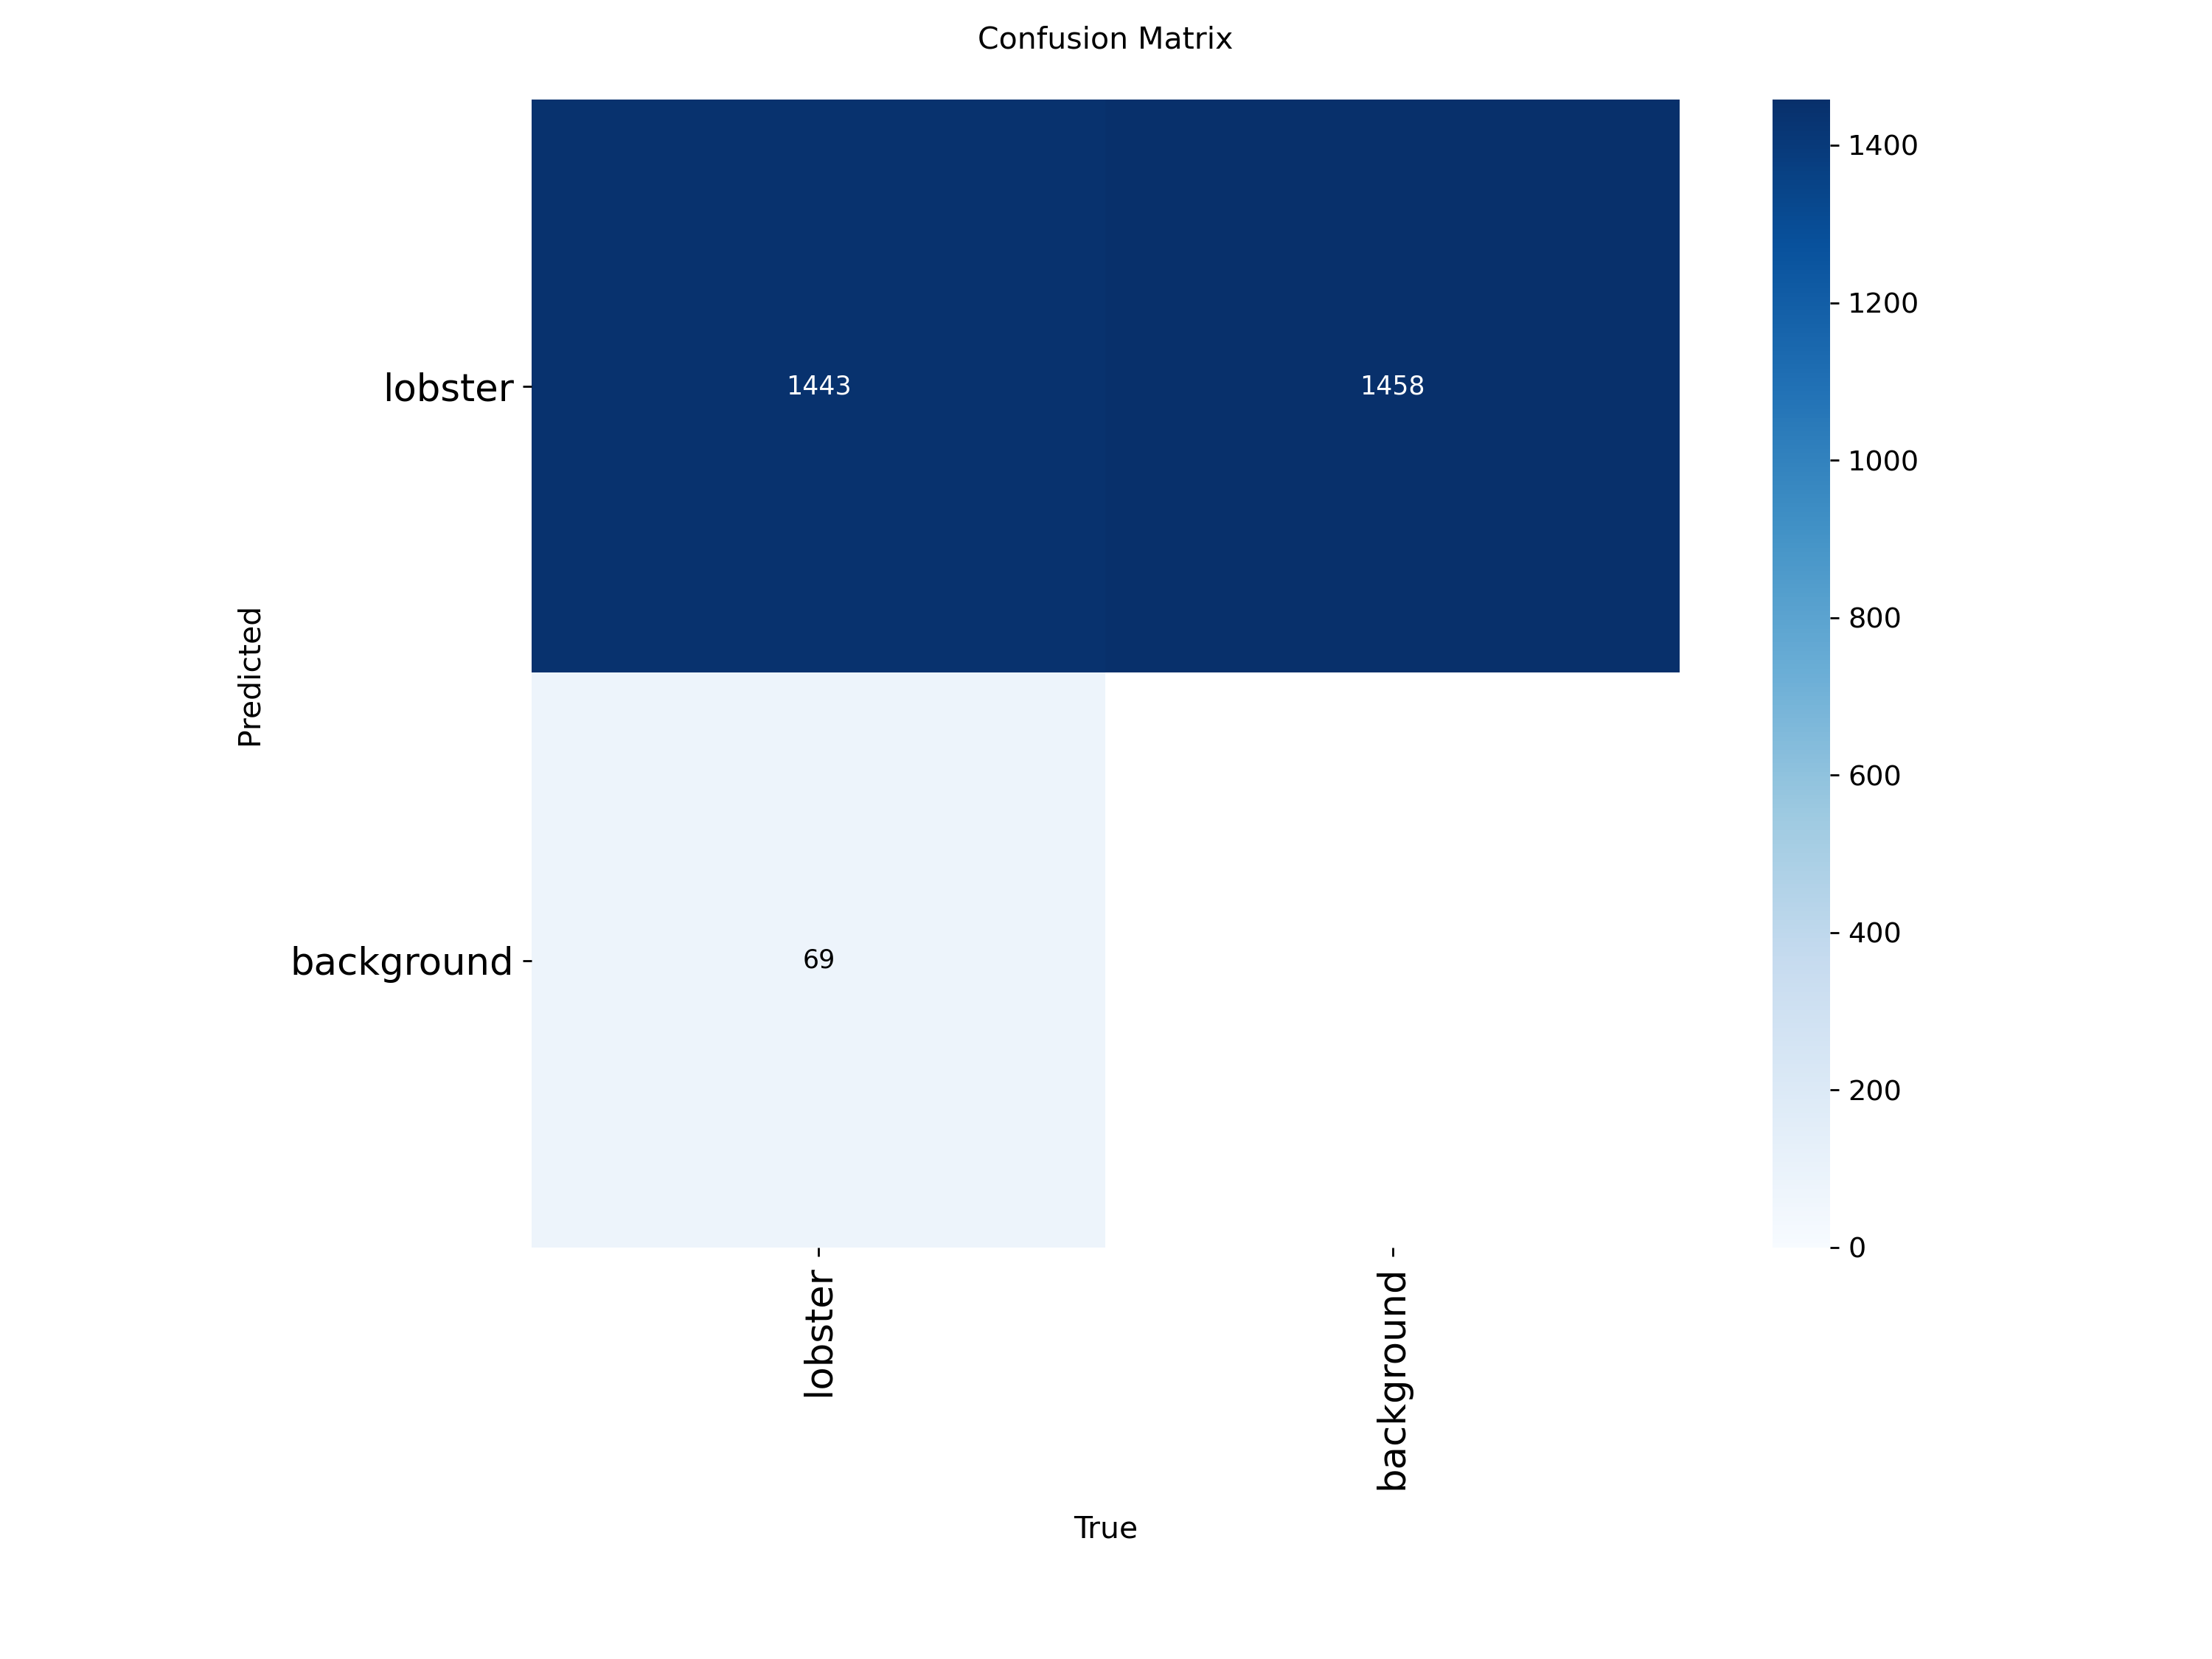

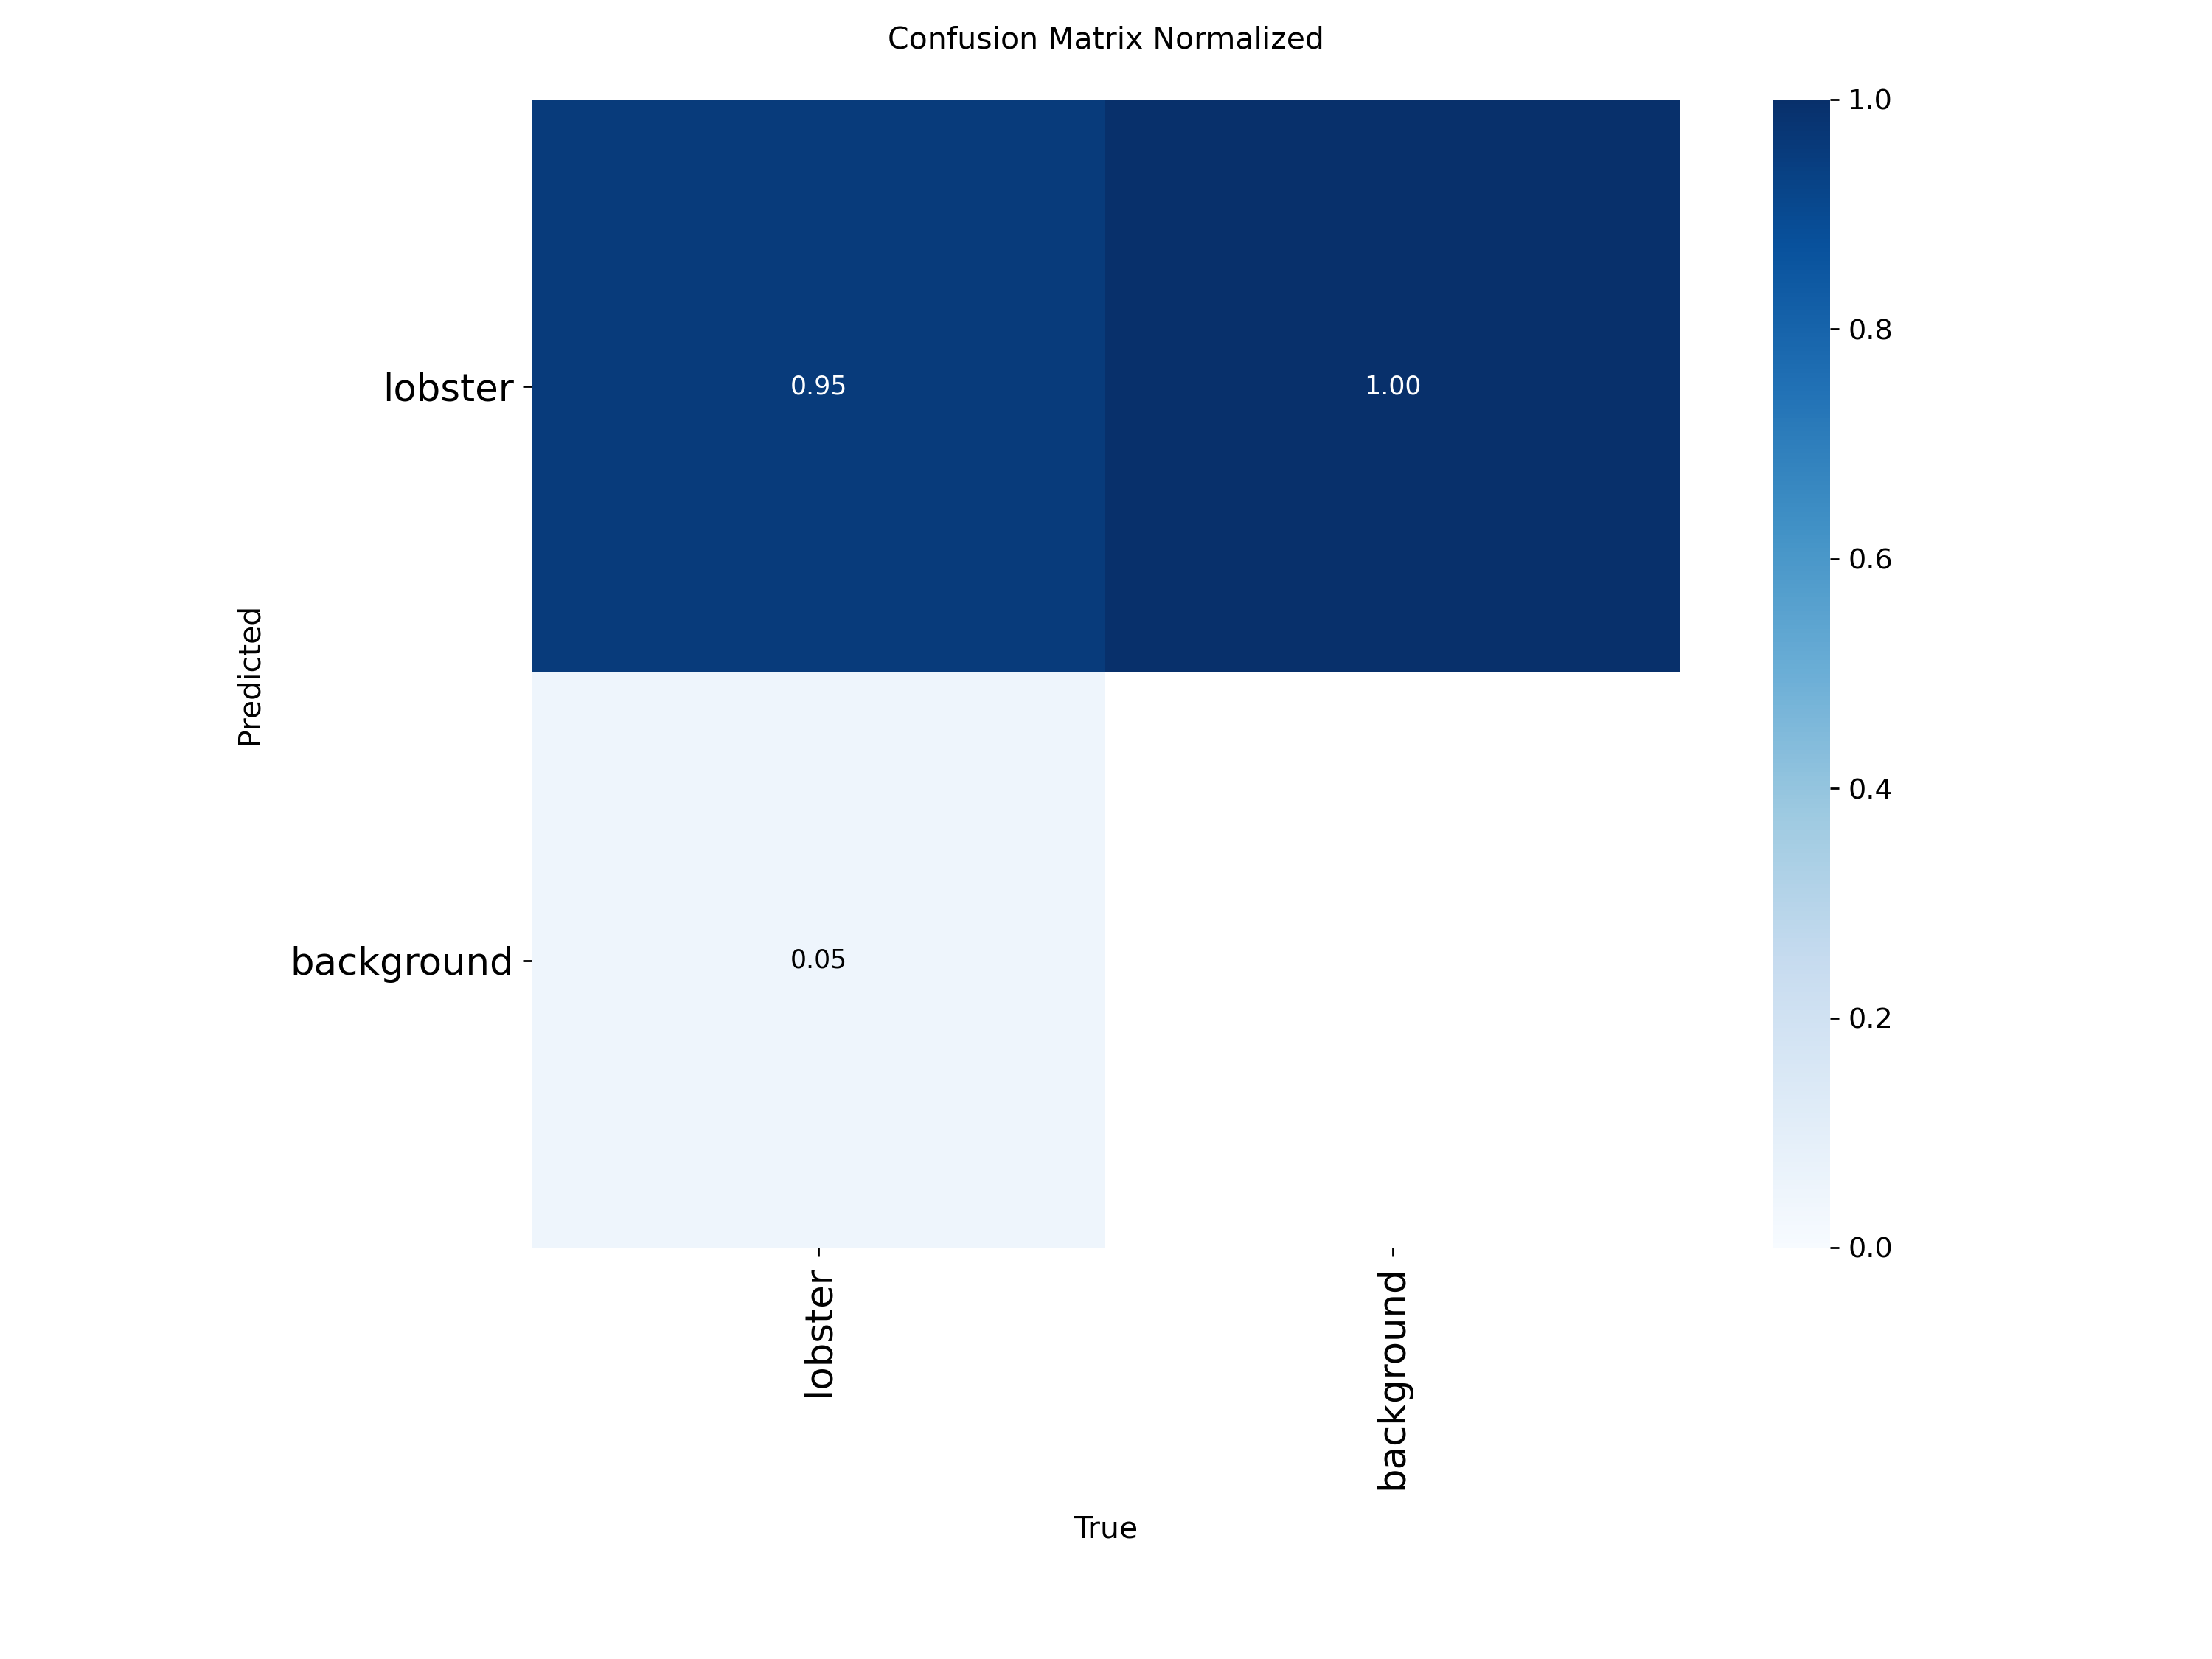

### Precision-recall curve

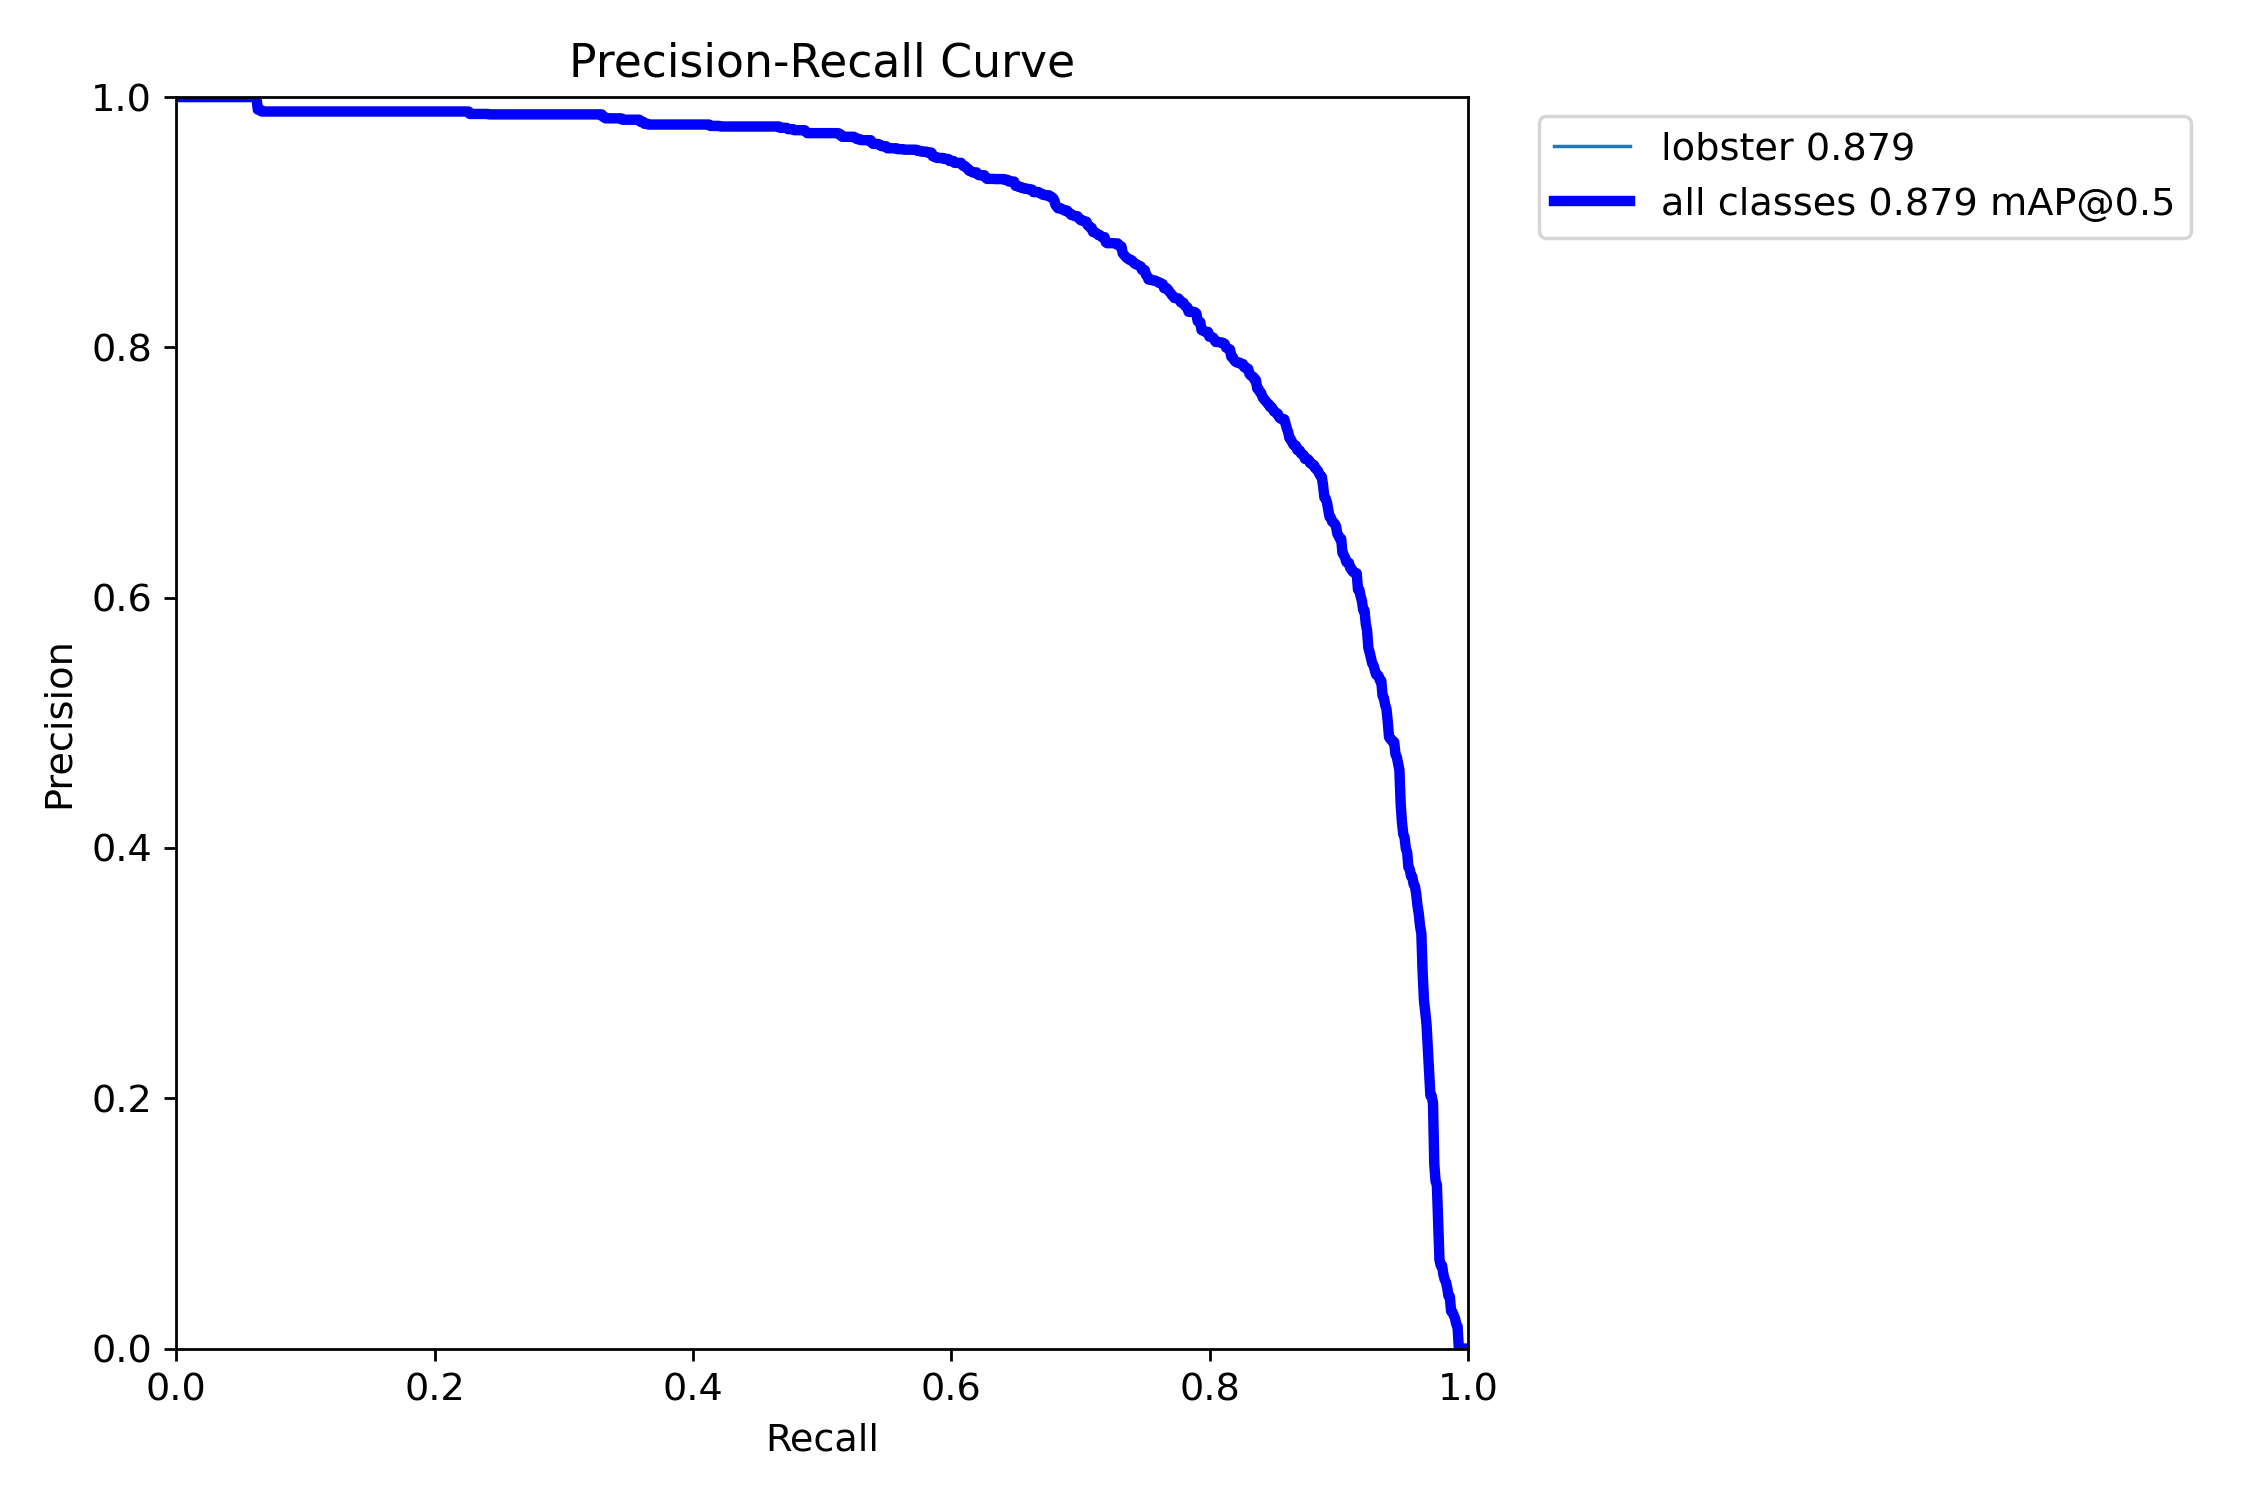

### F1 curve

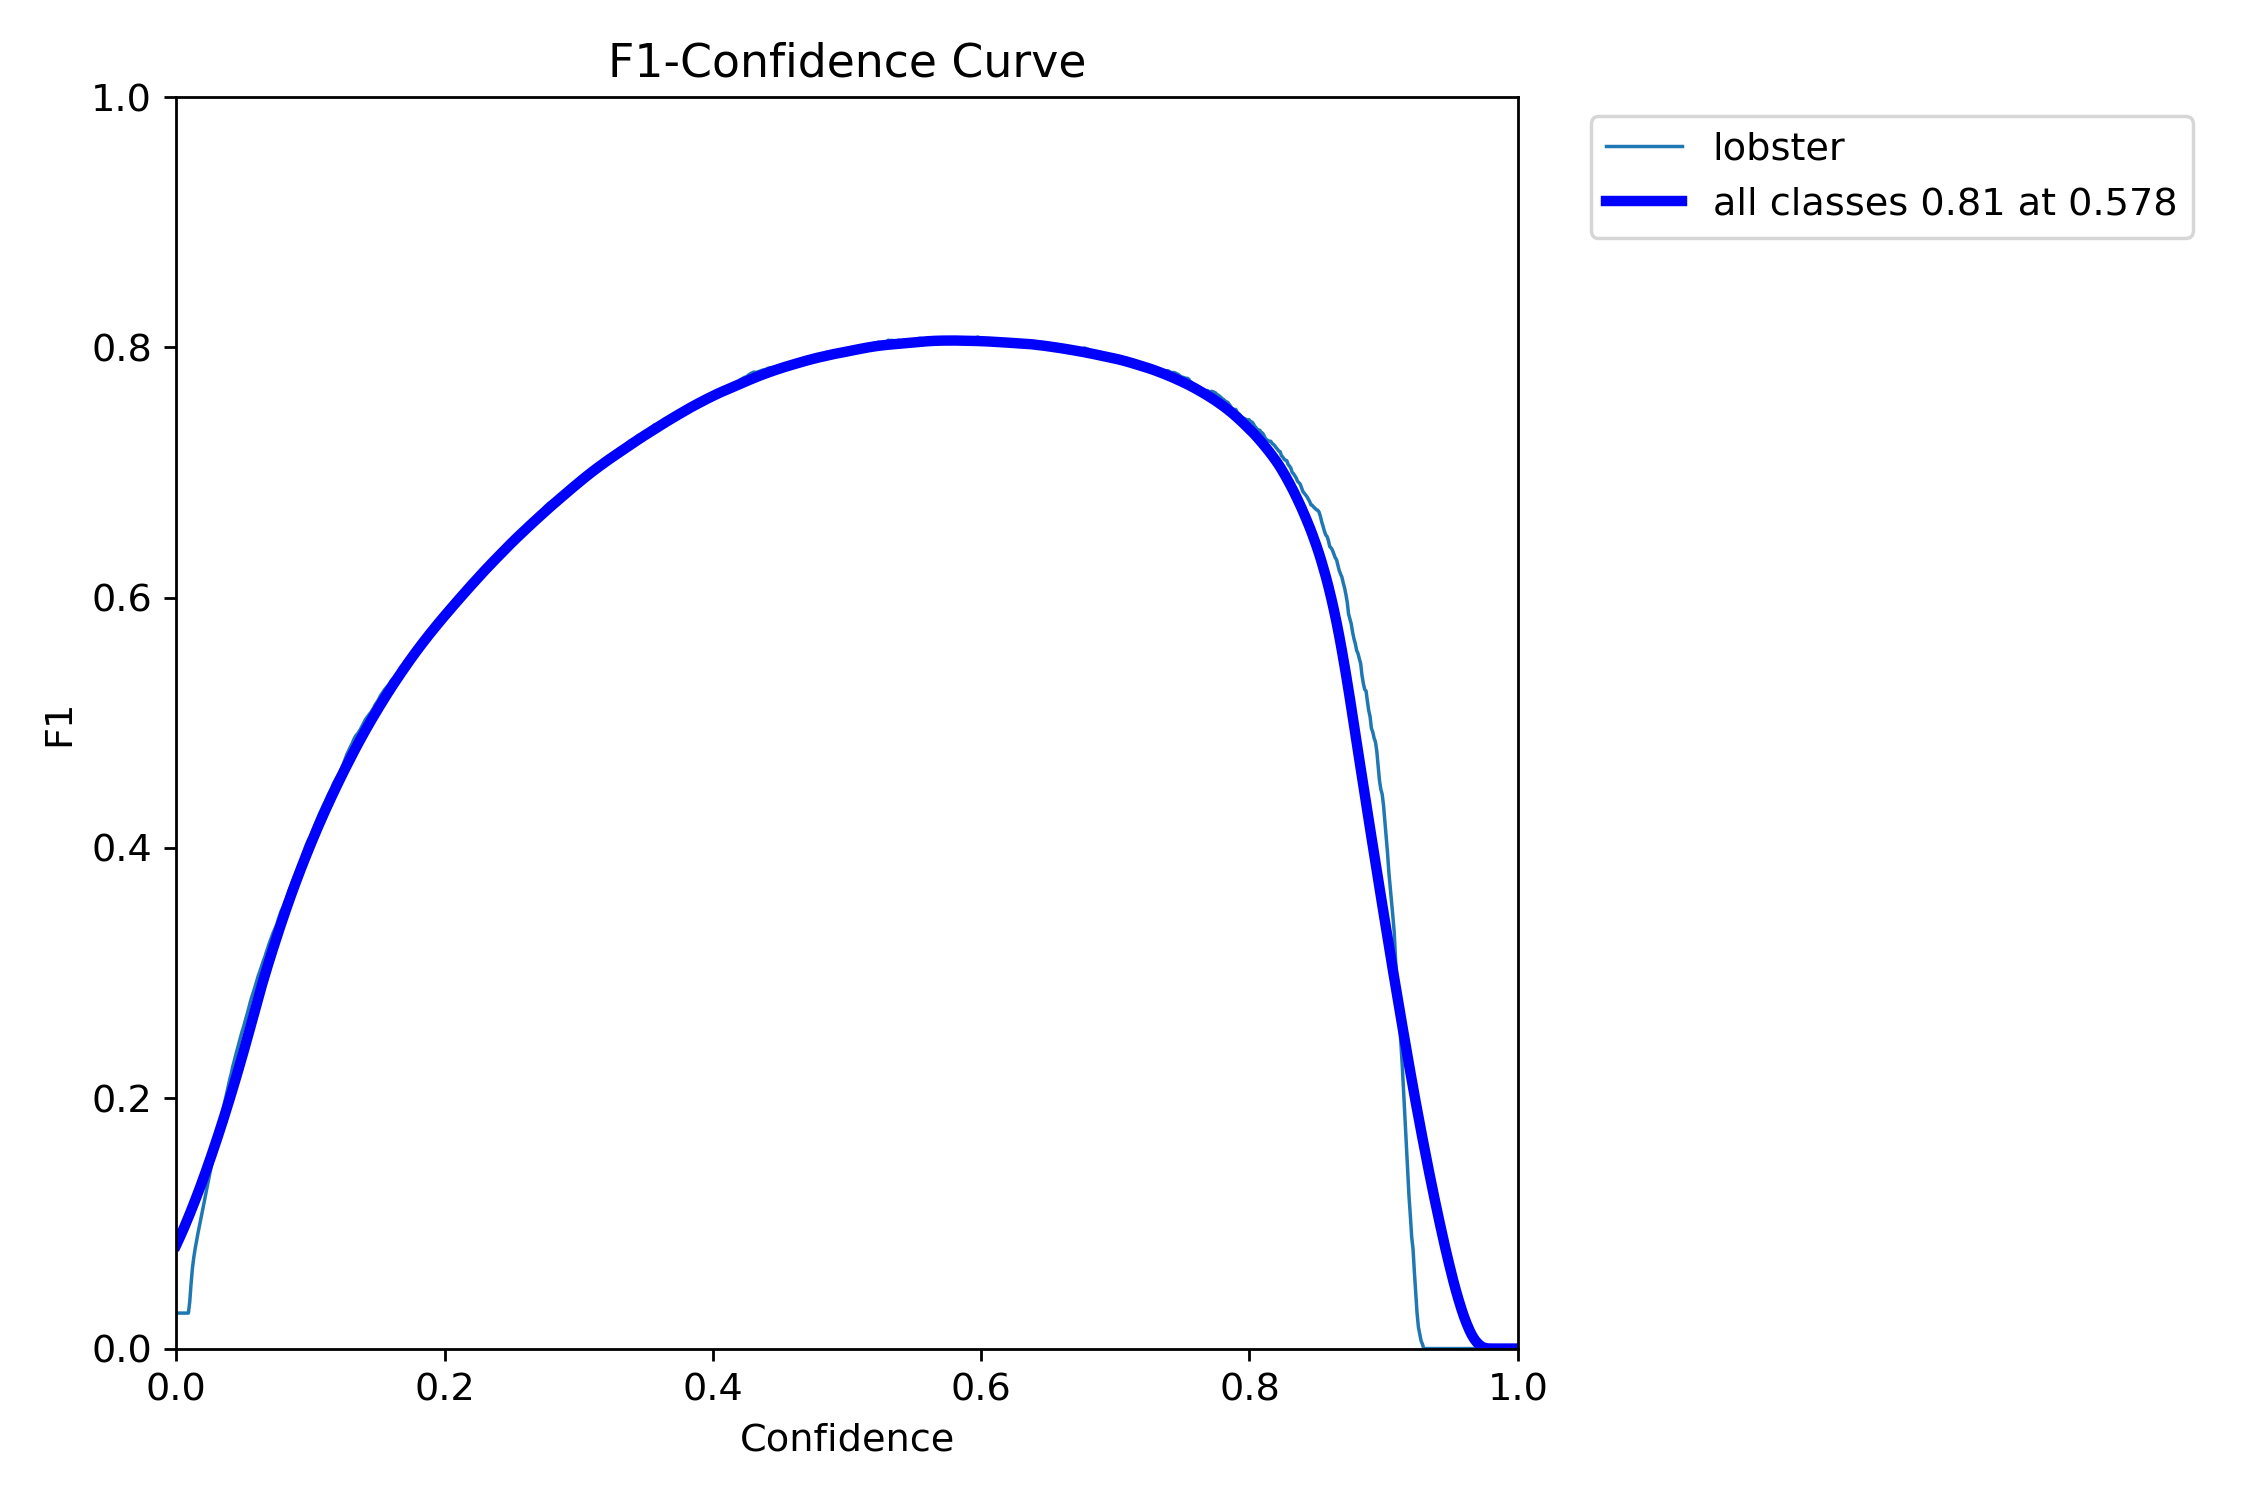

### Prediction examples at the val-chosen confidence (0.619)

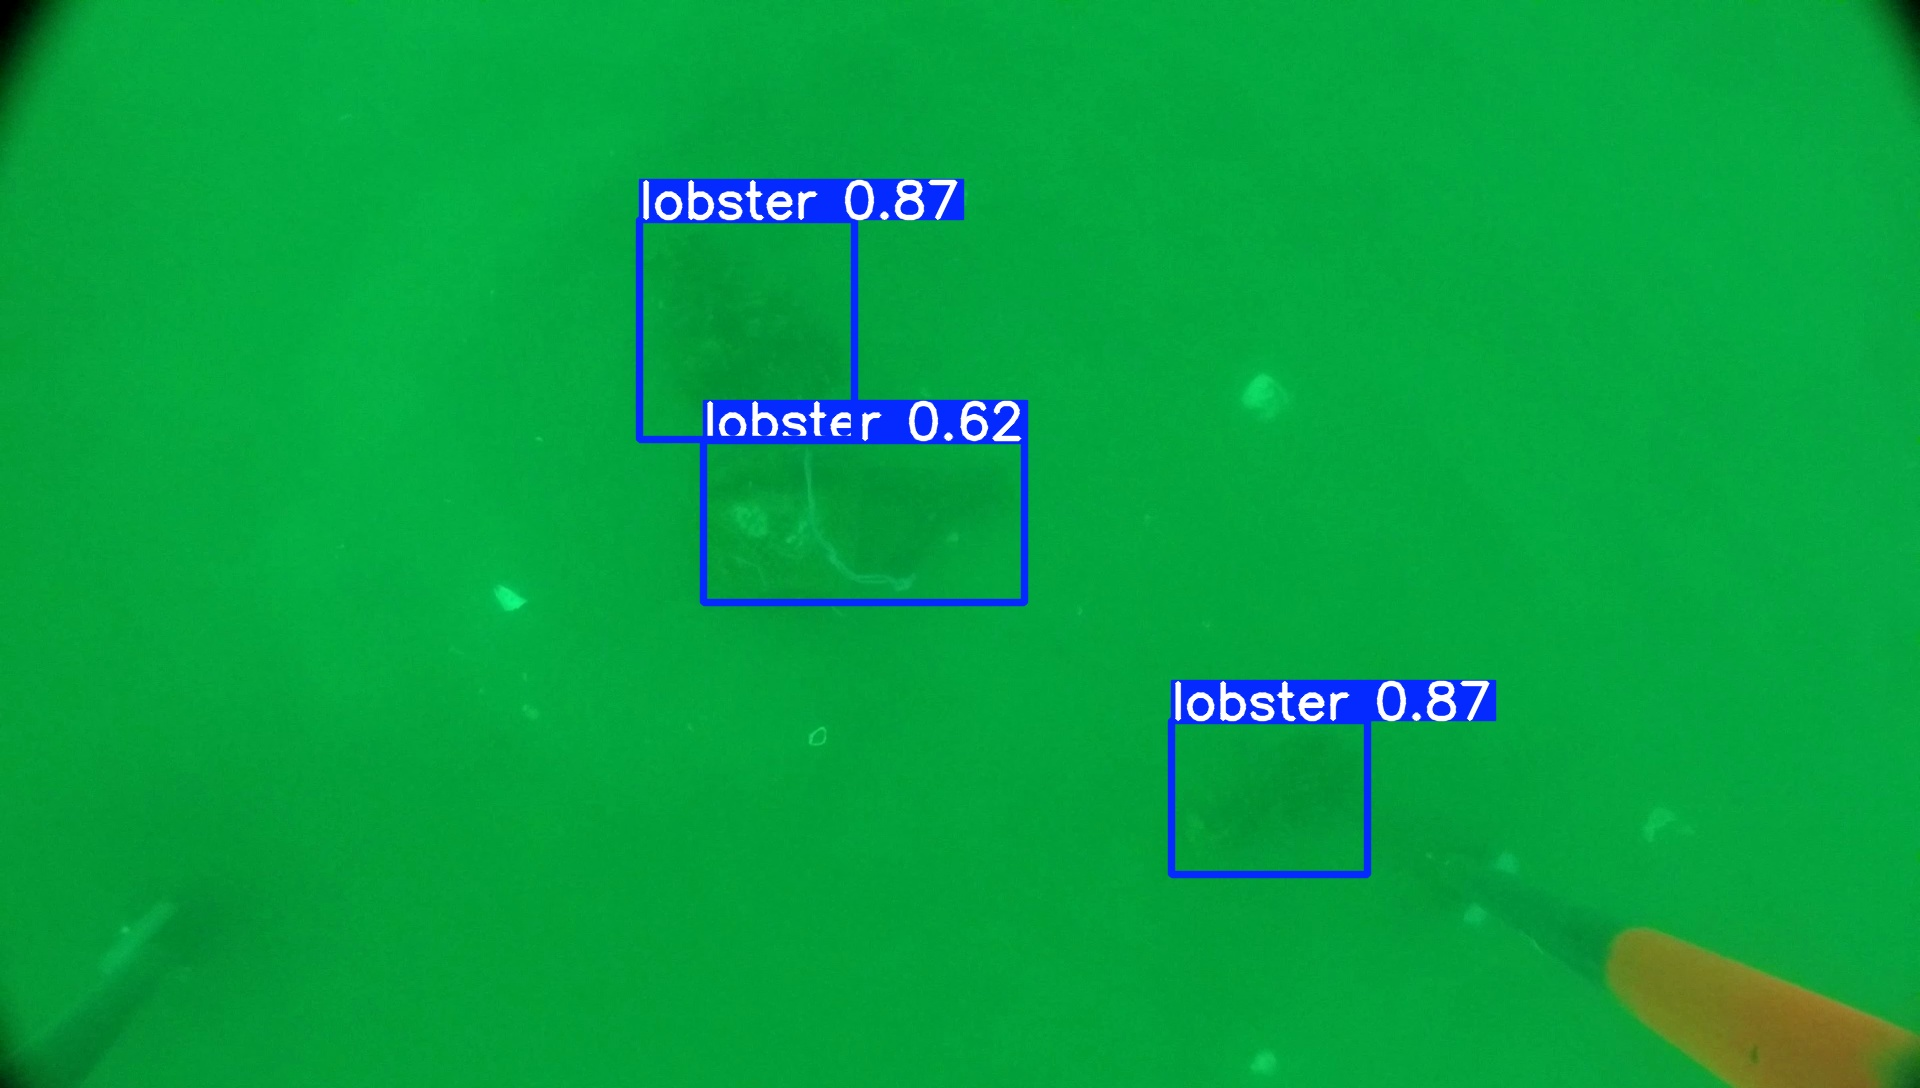

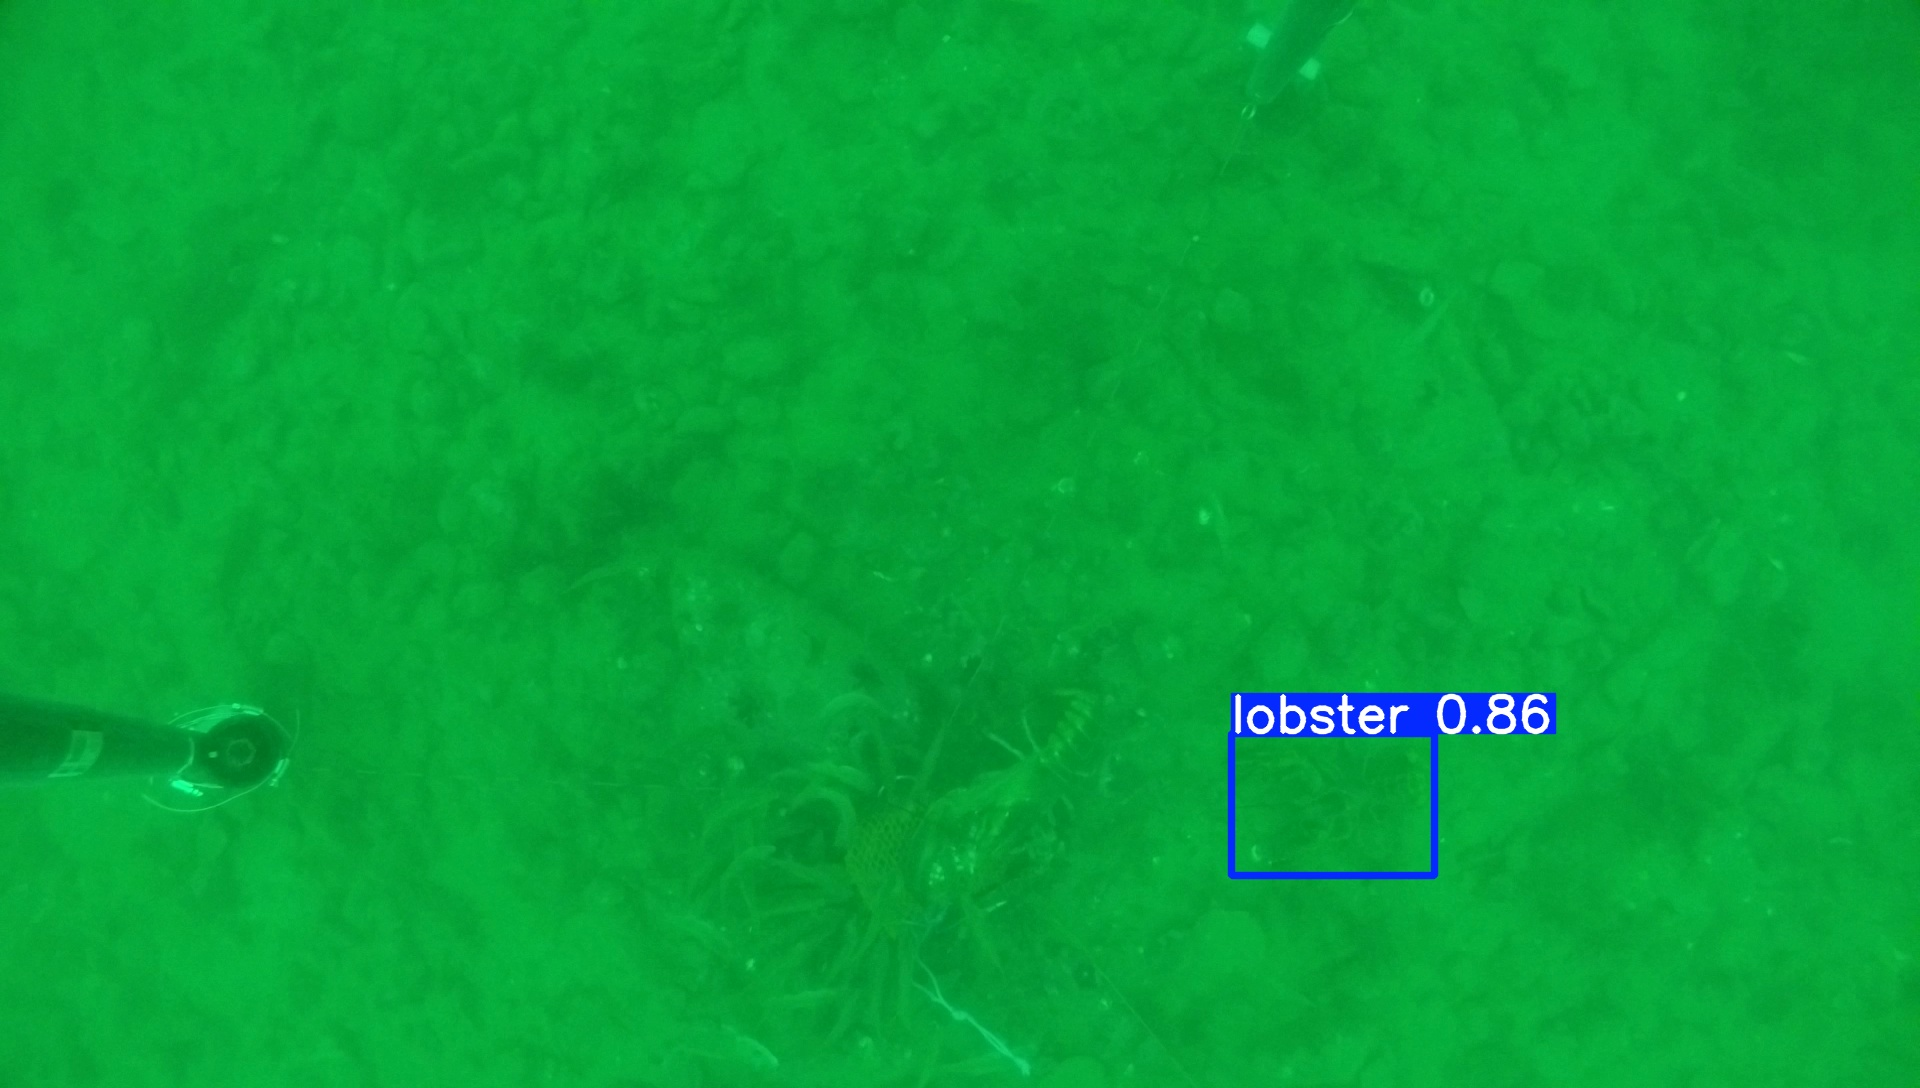

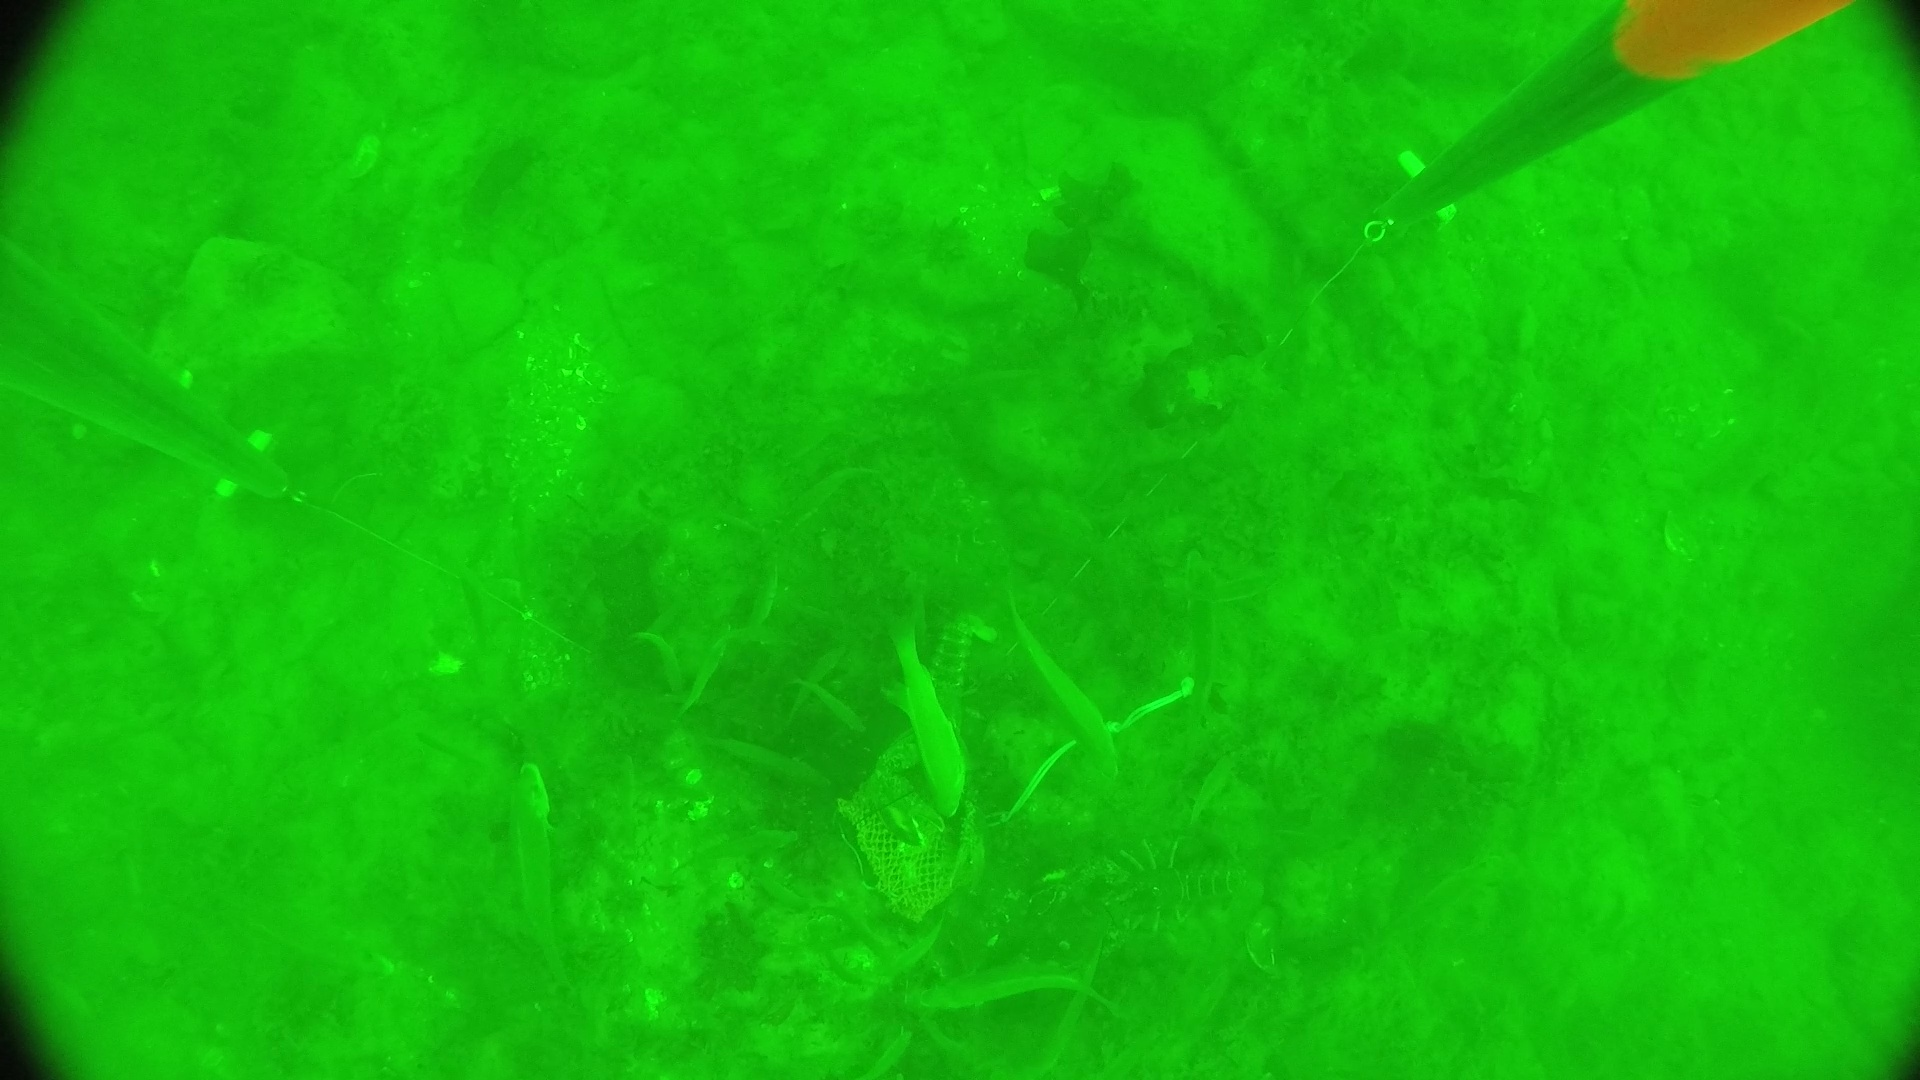

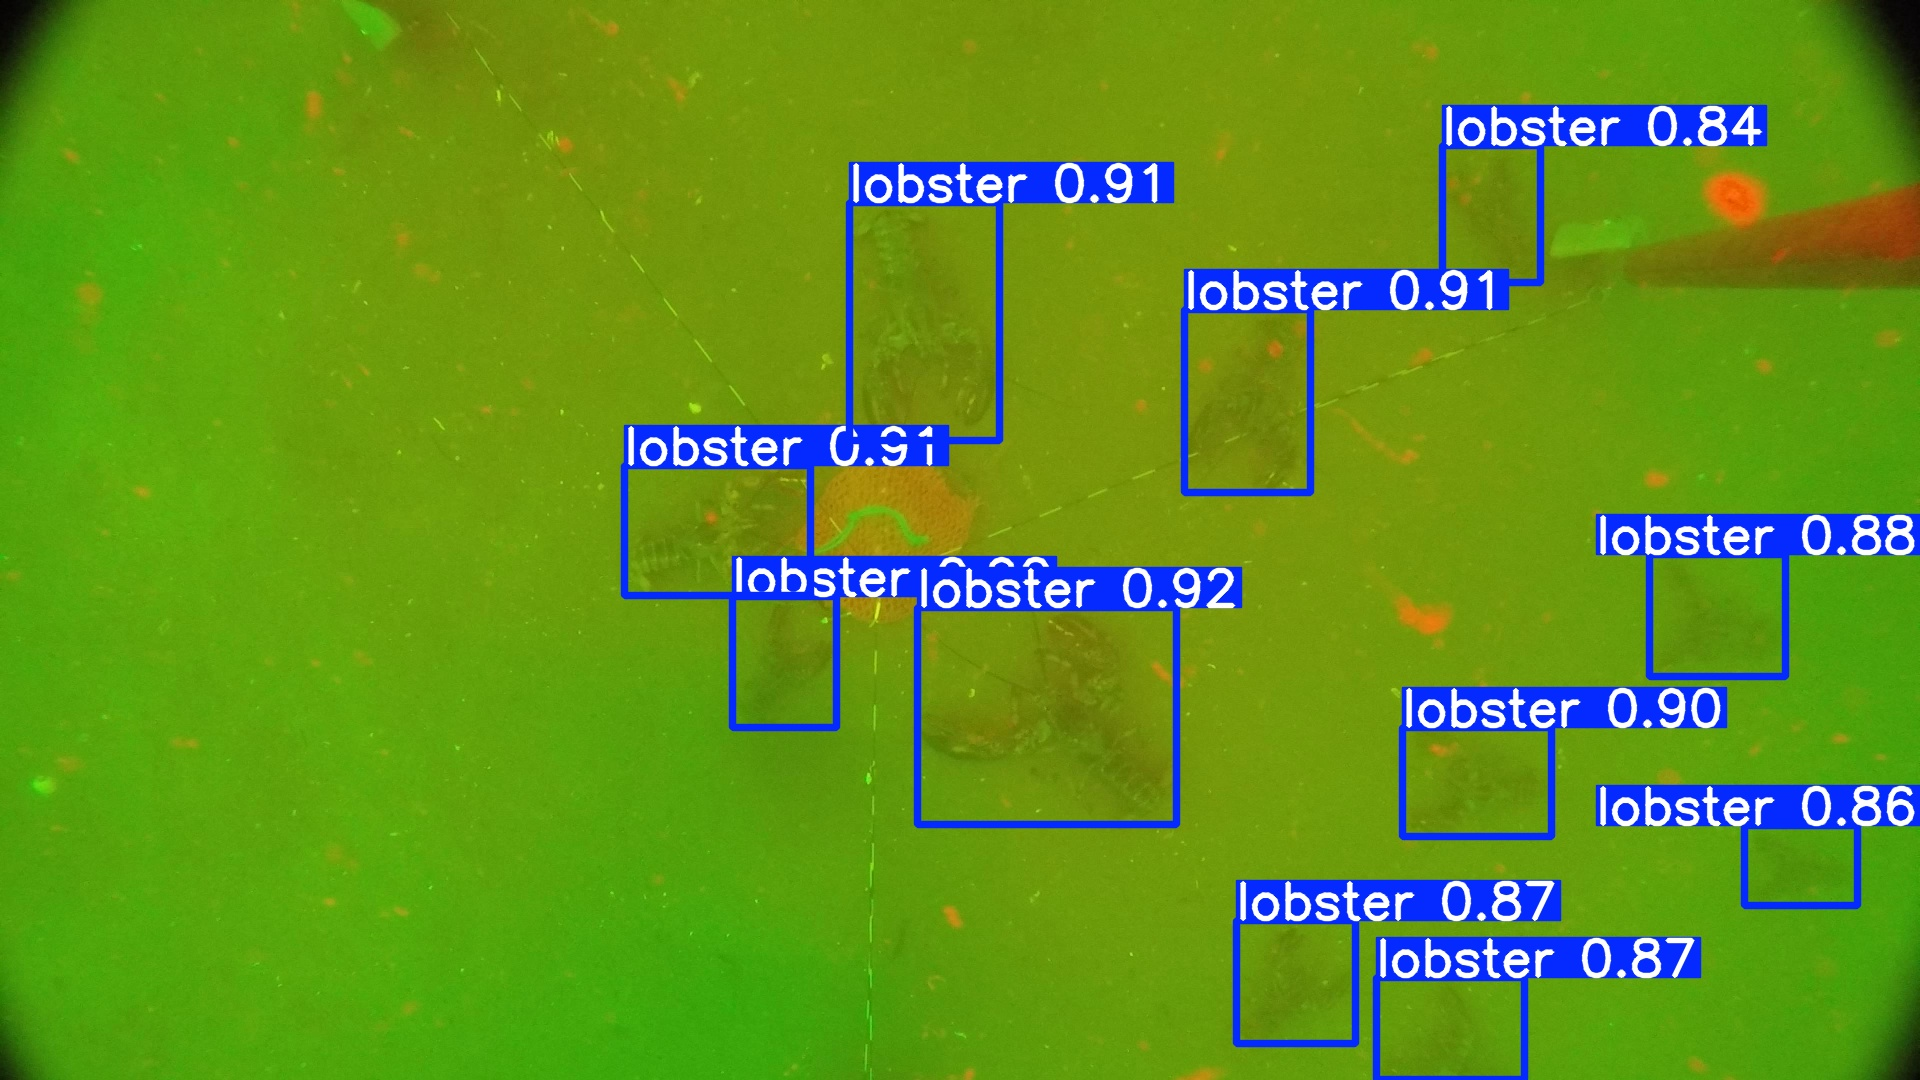

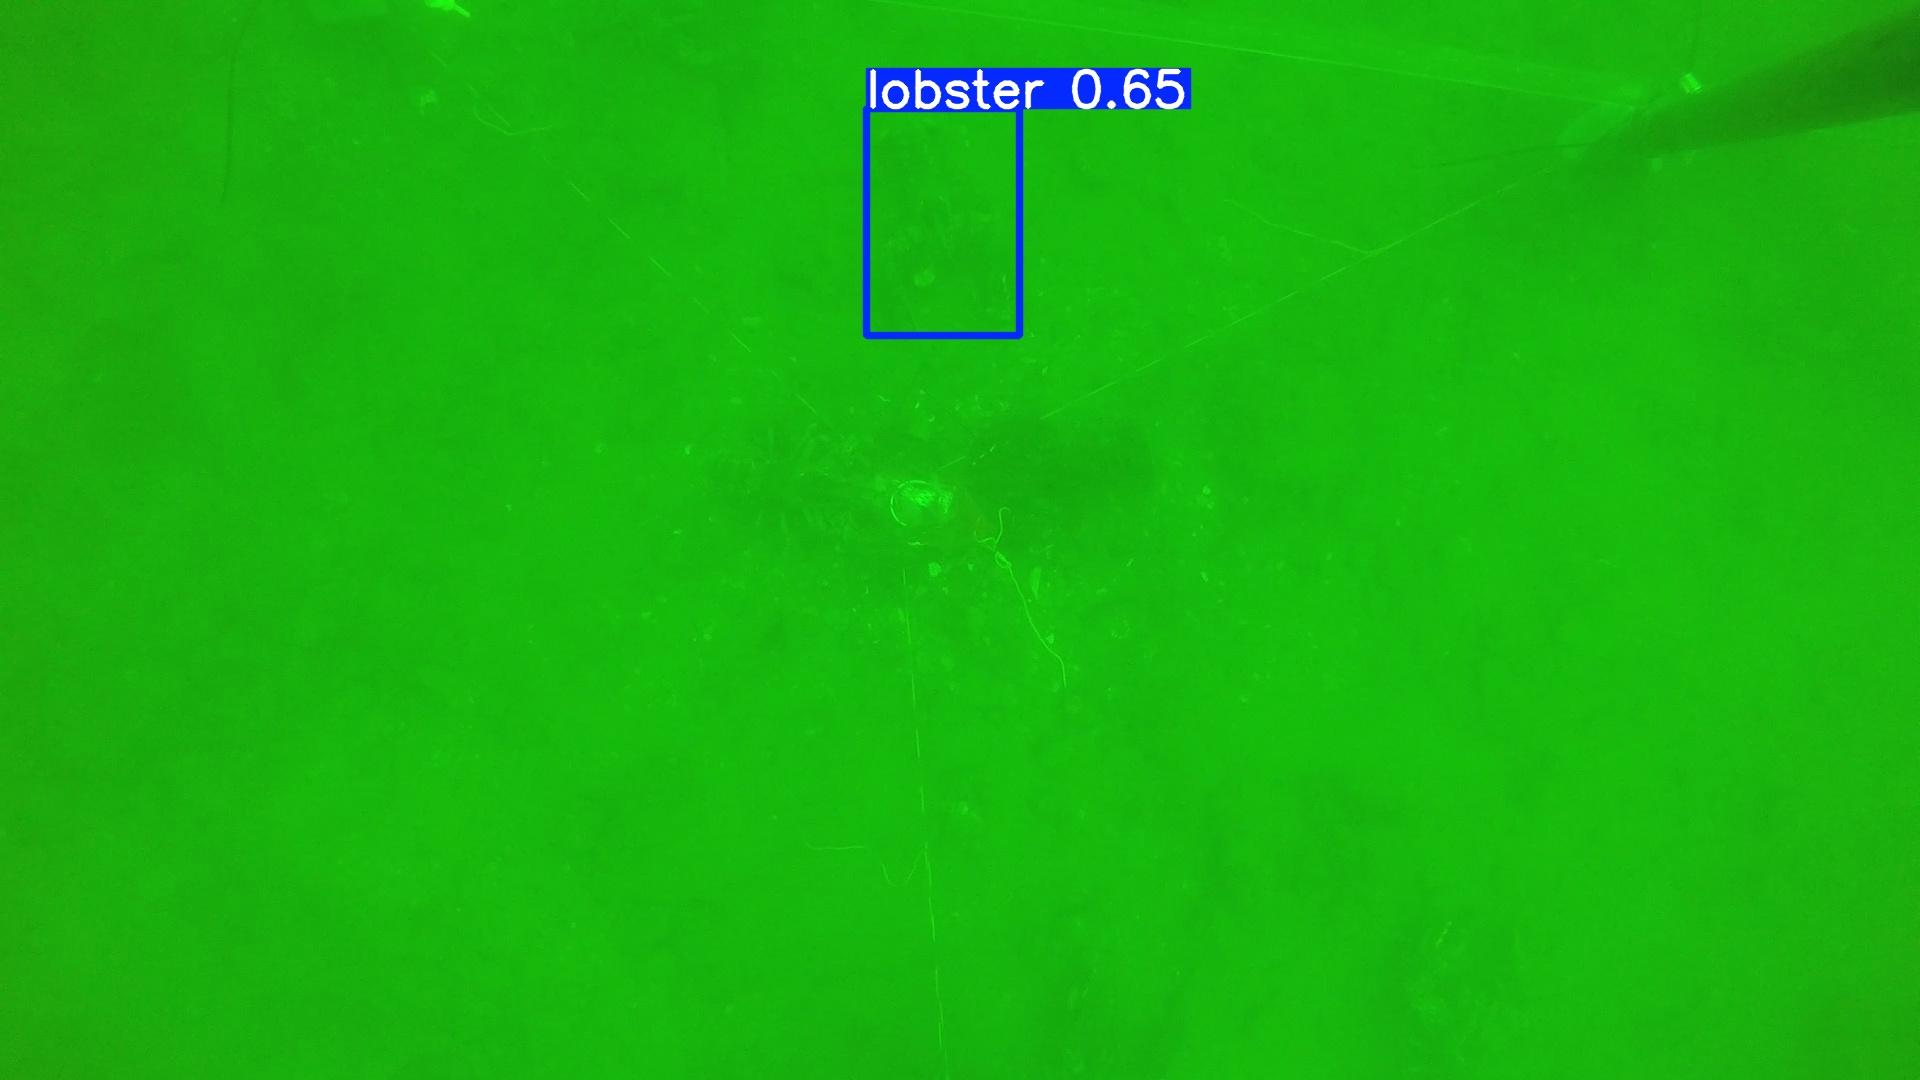

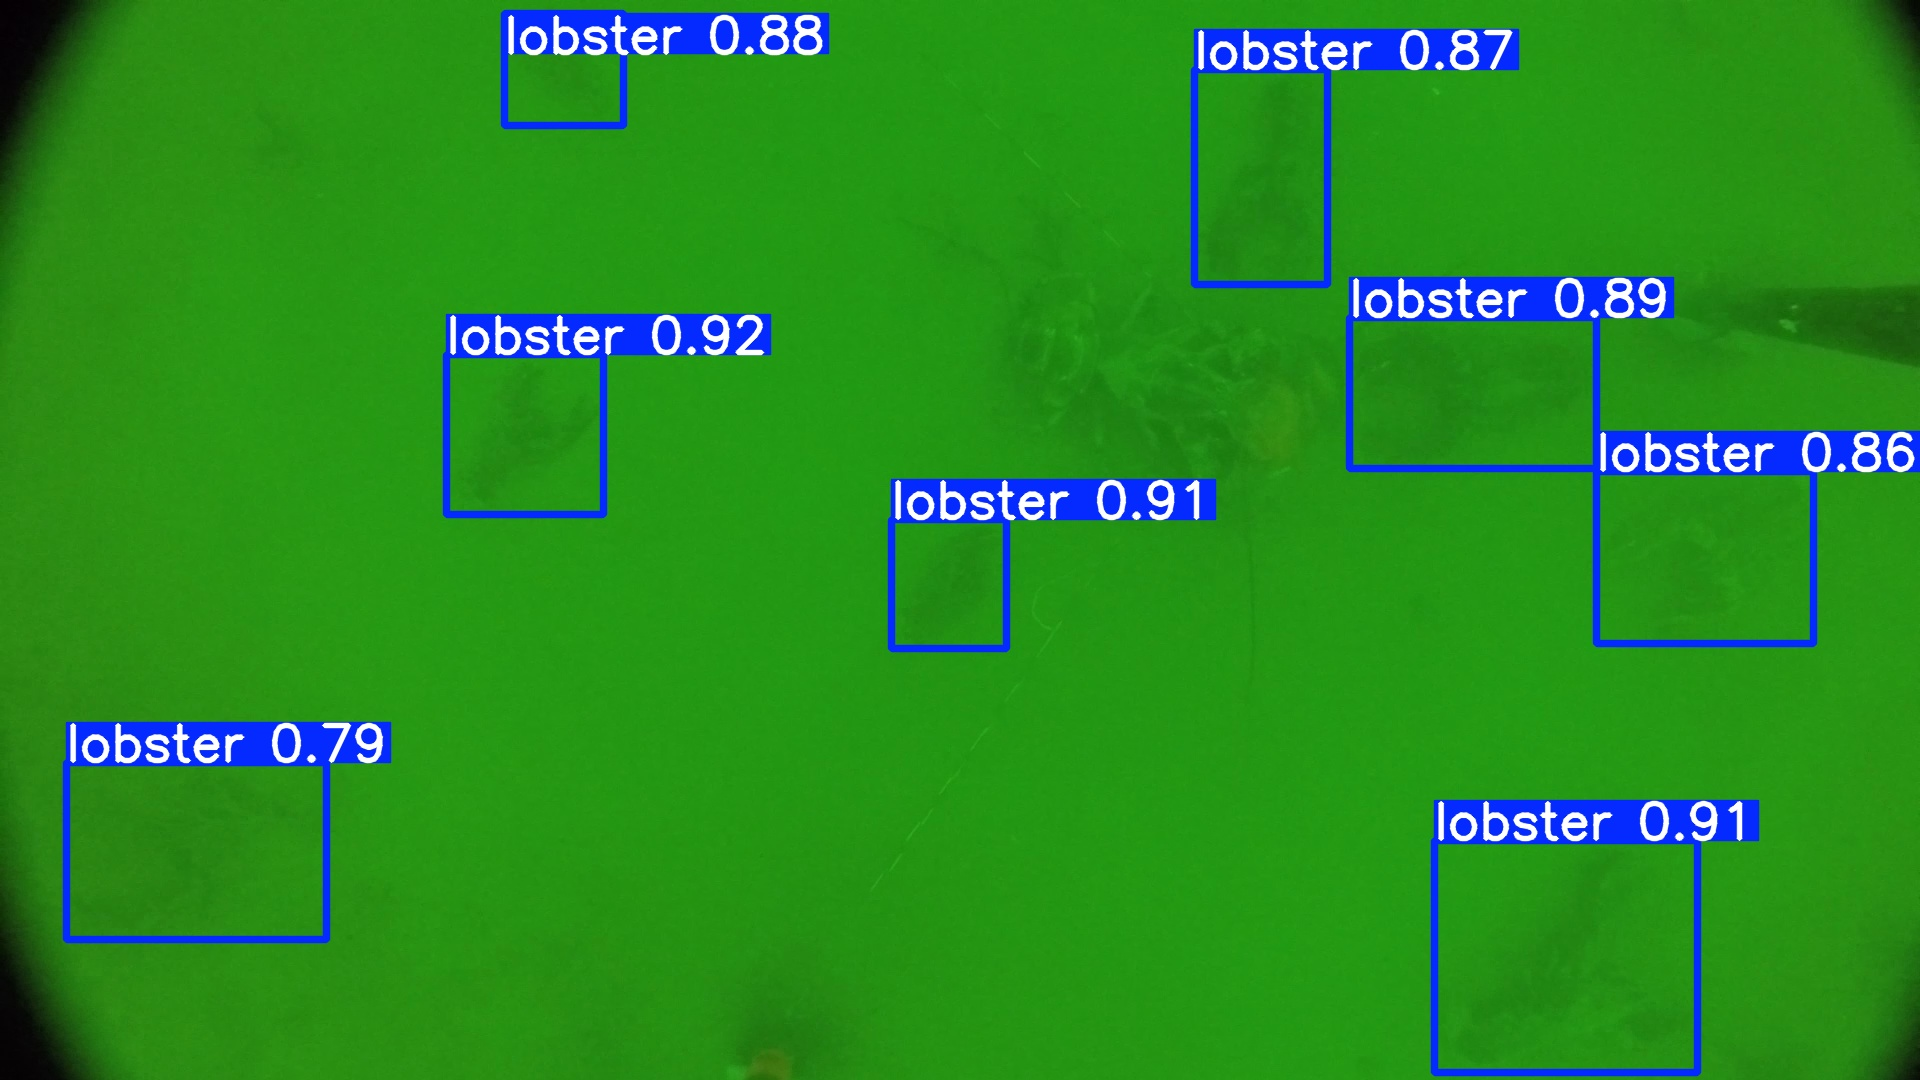

### Ultralytics validation batches (labels vs predictions with confidence)

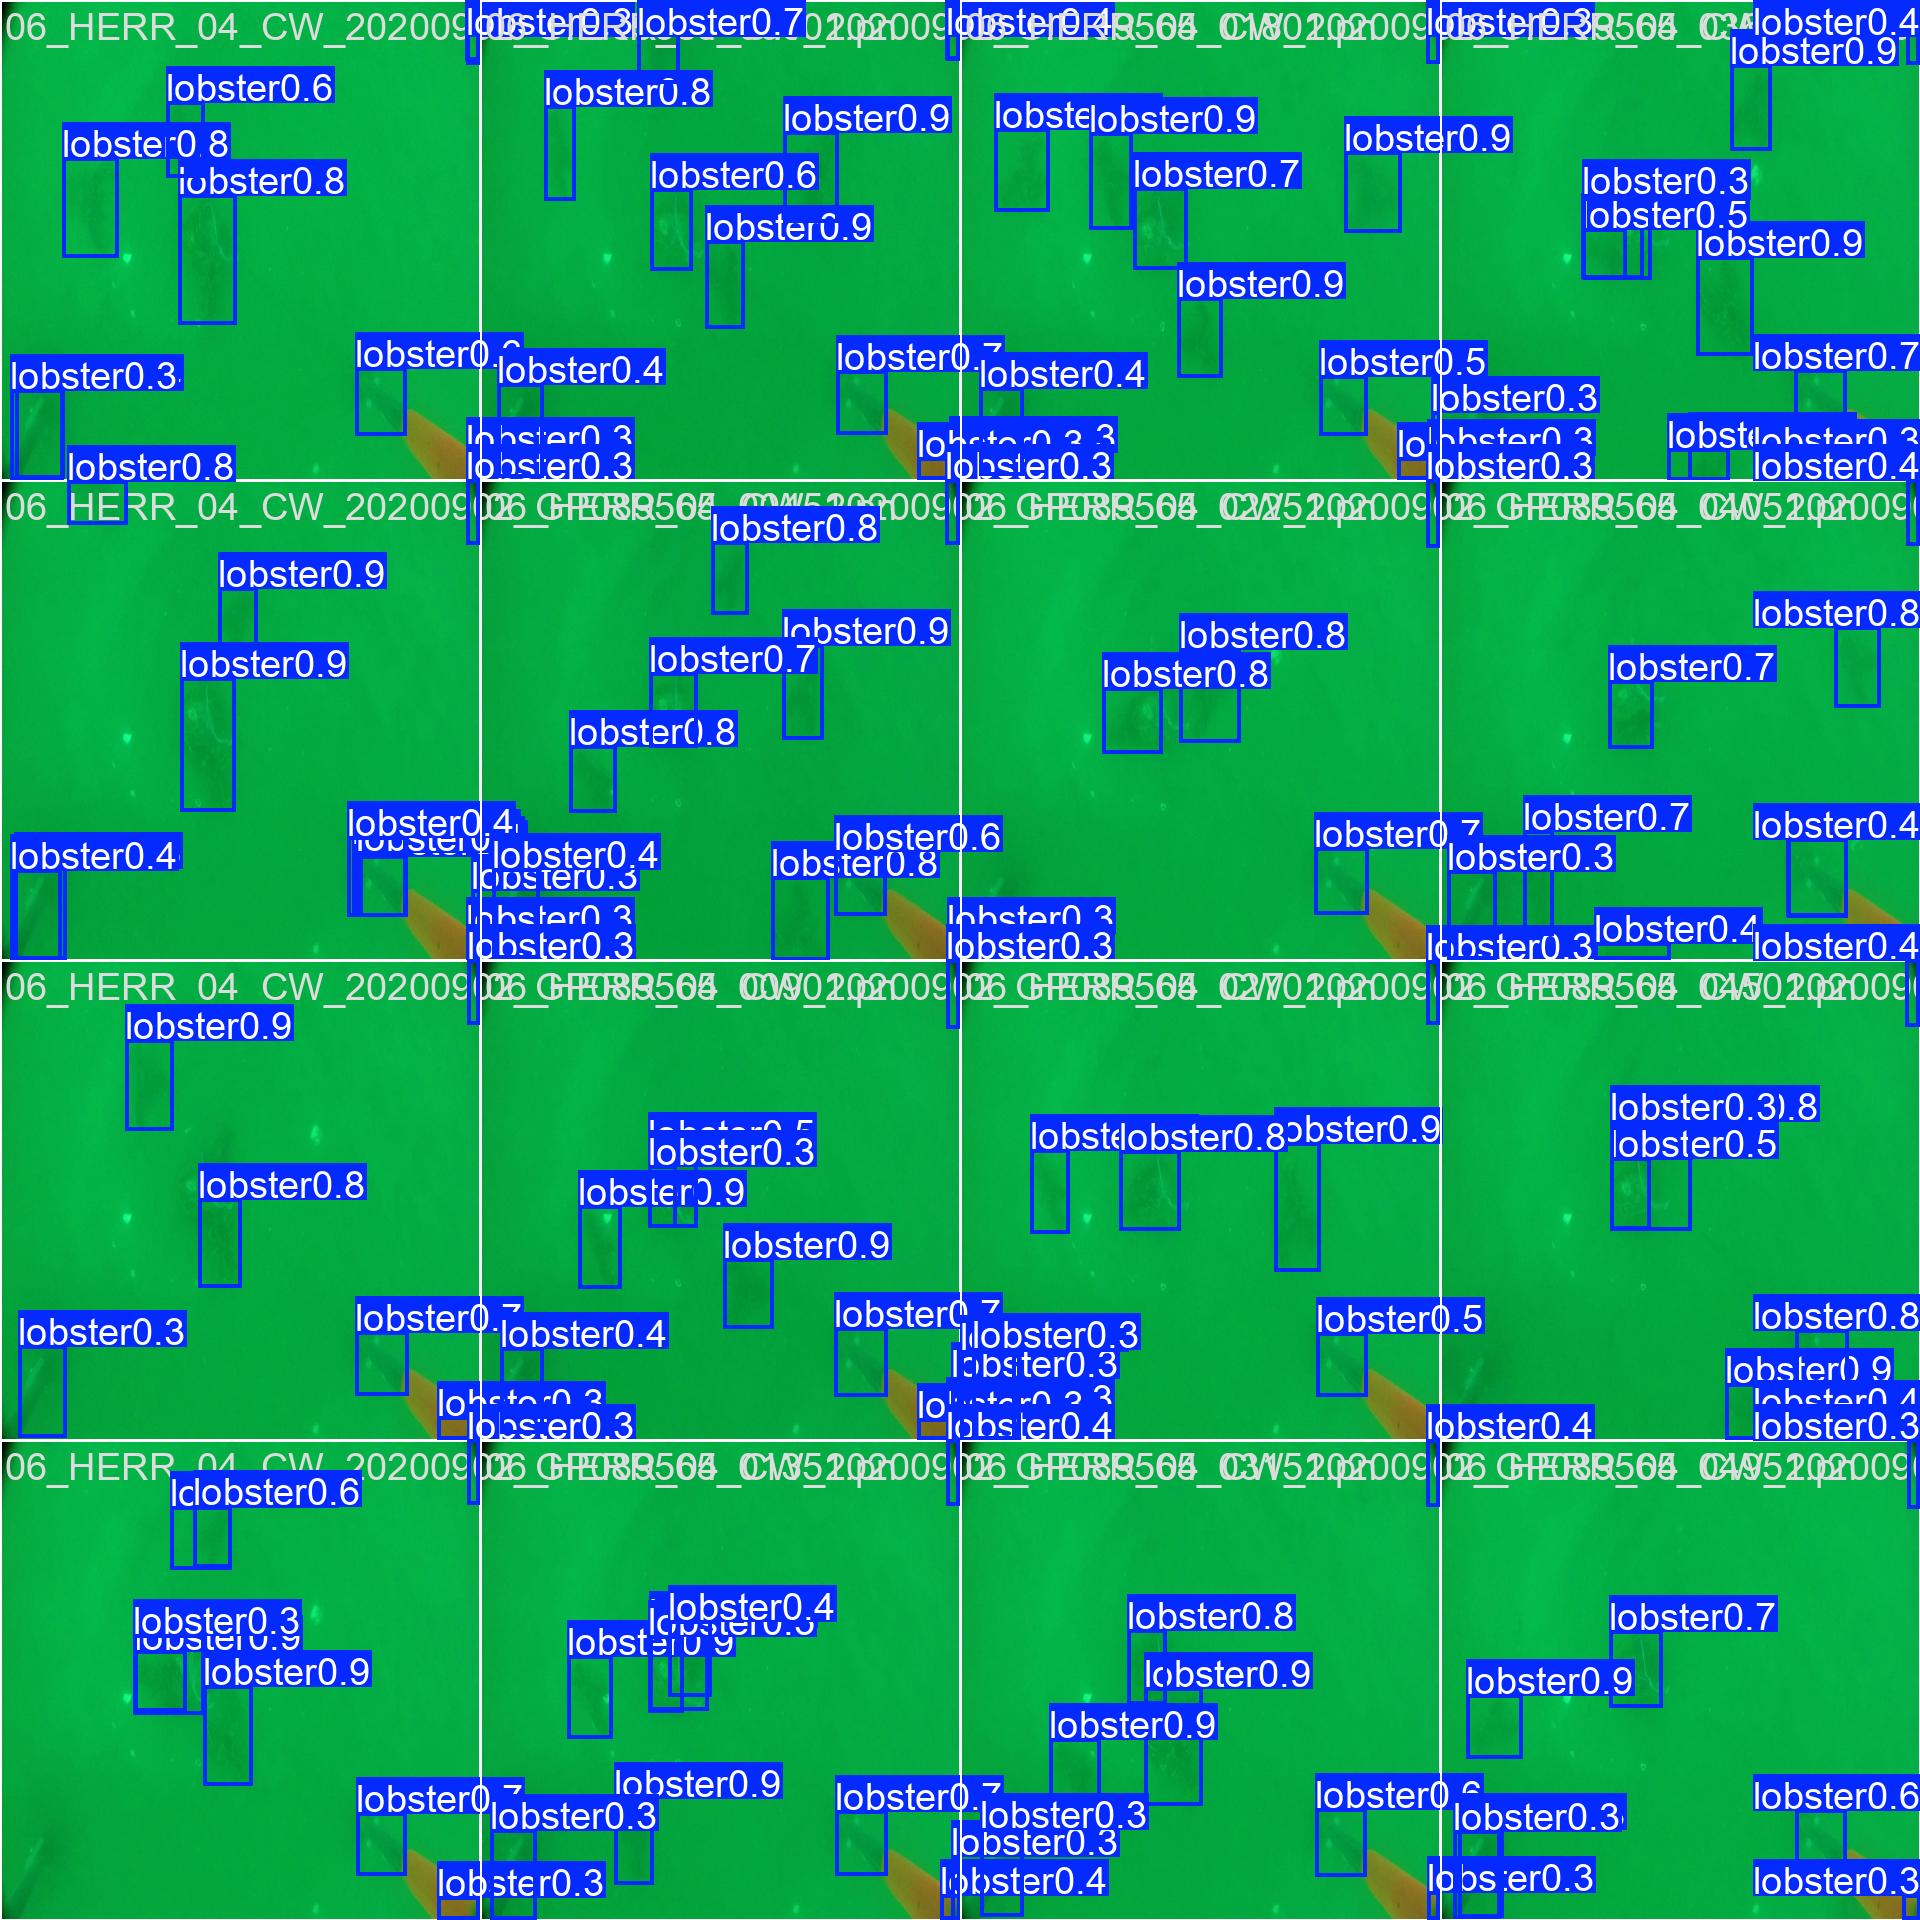

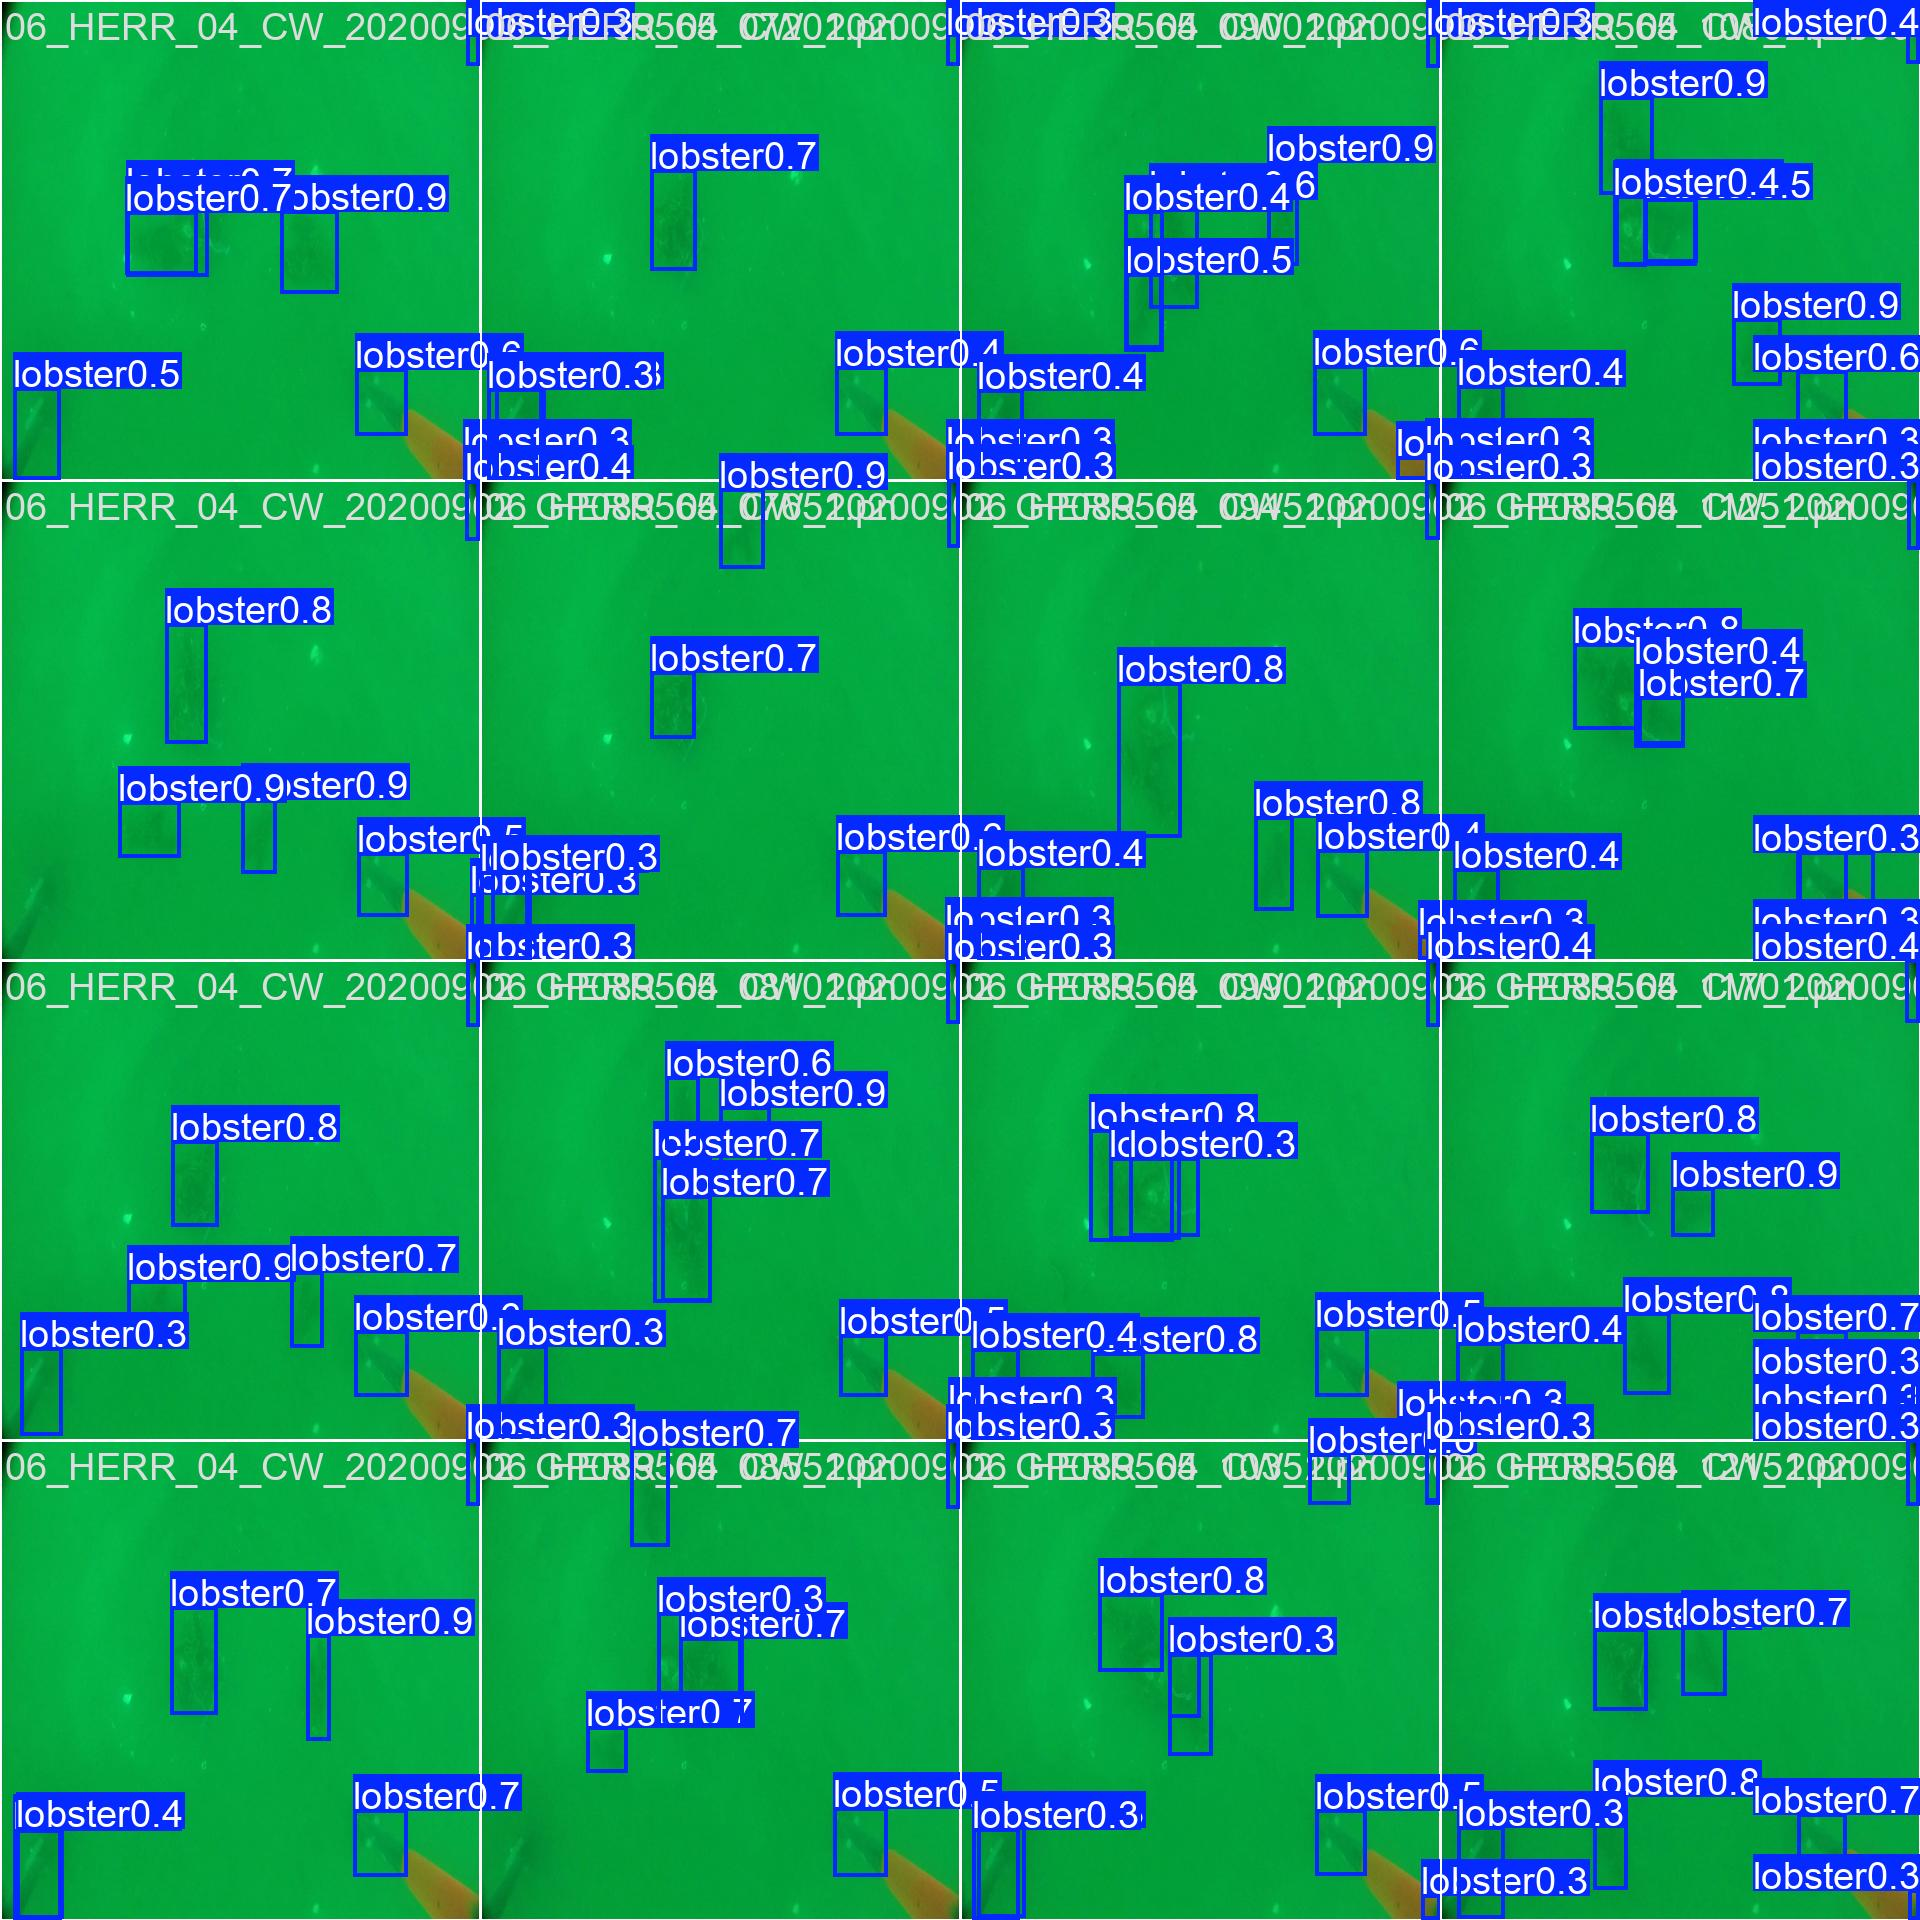

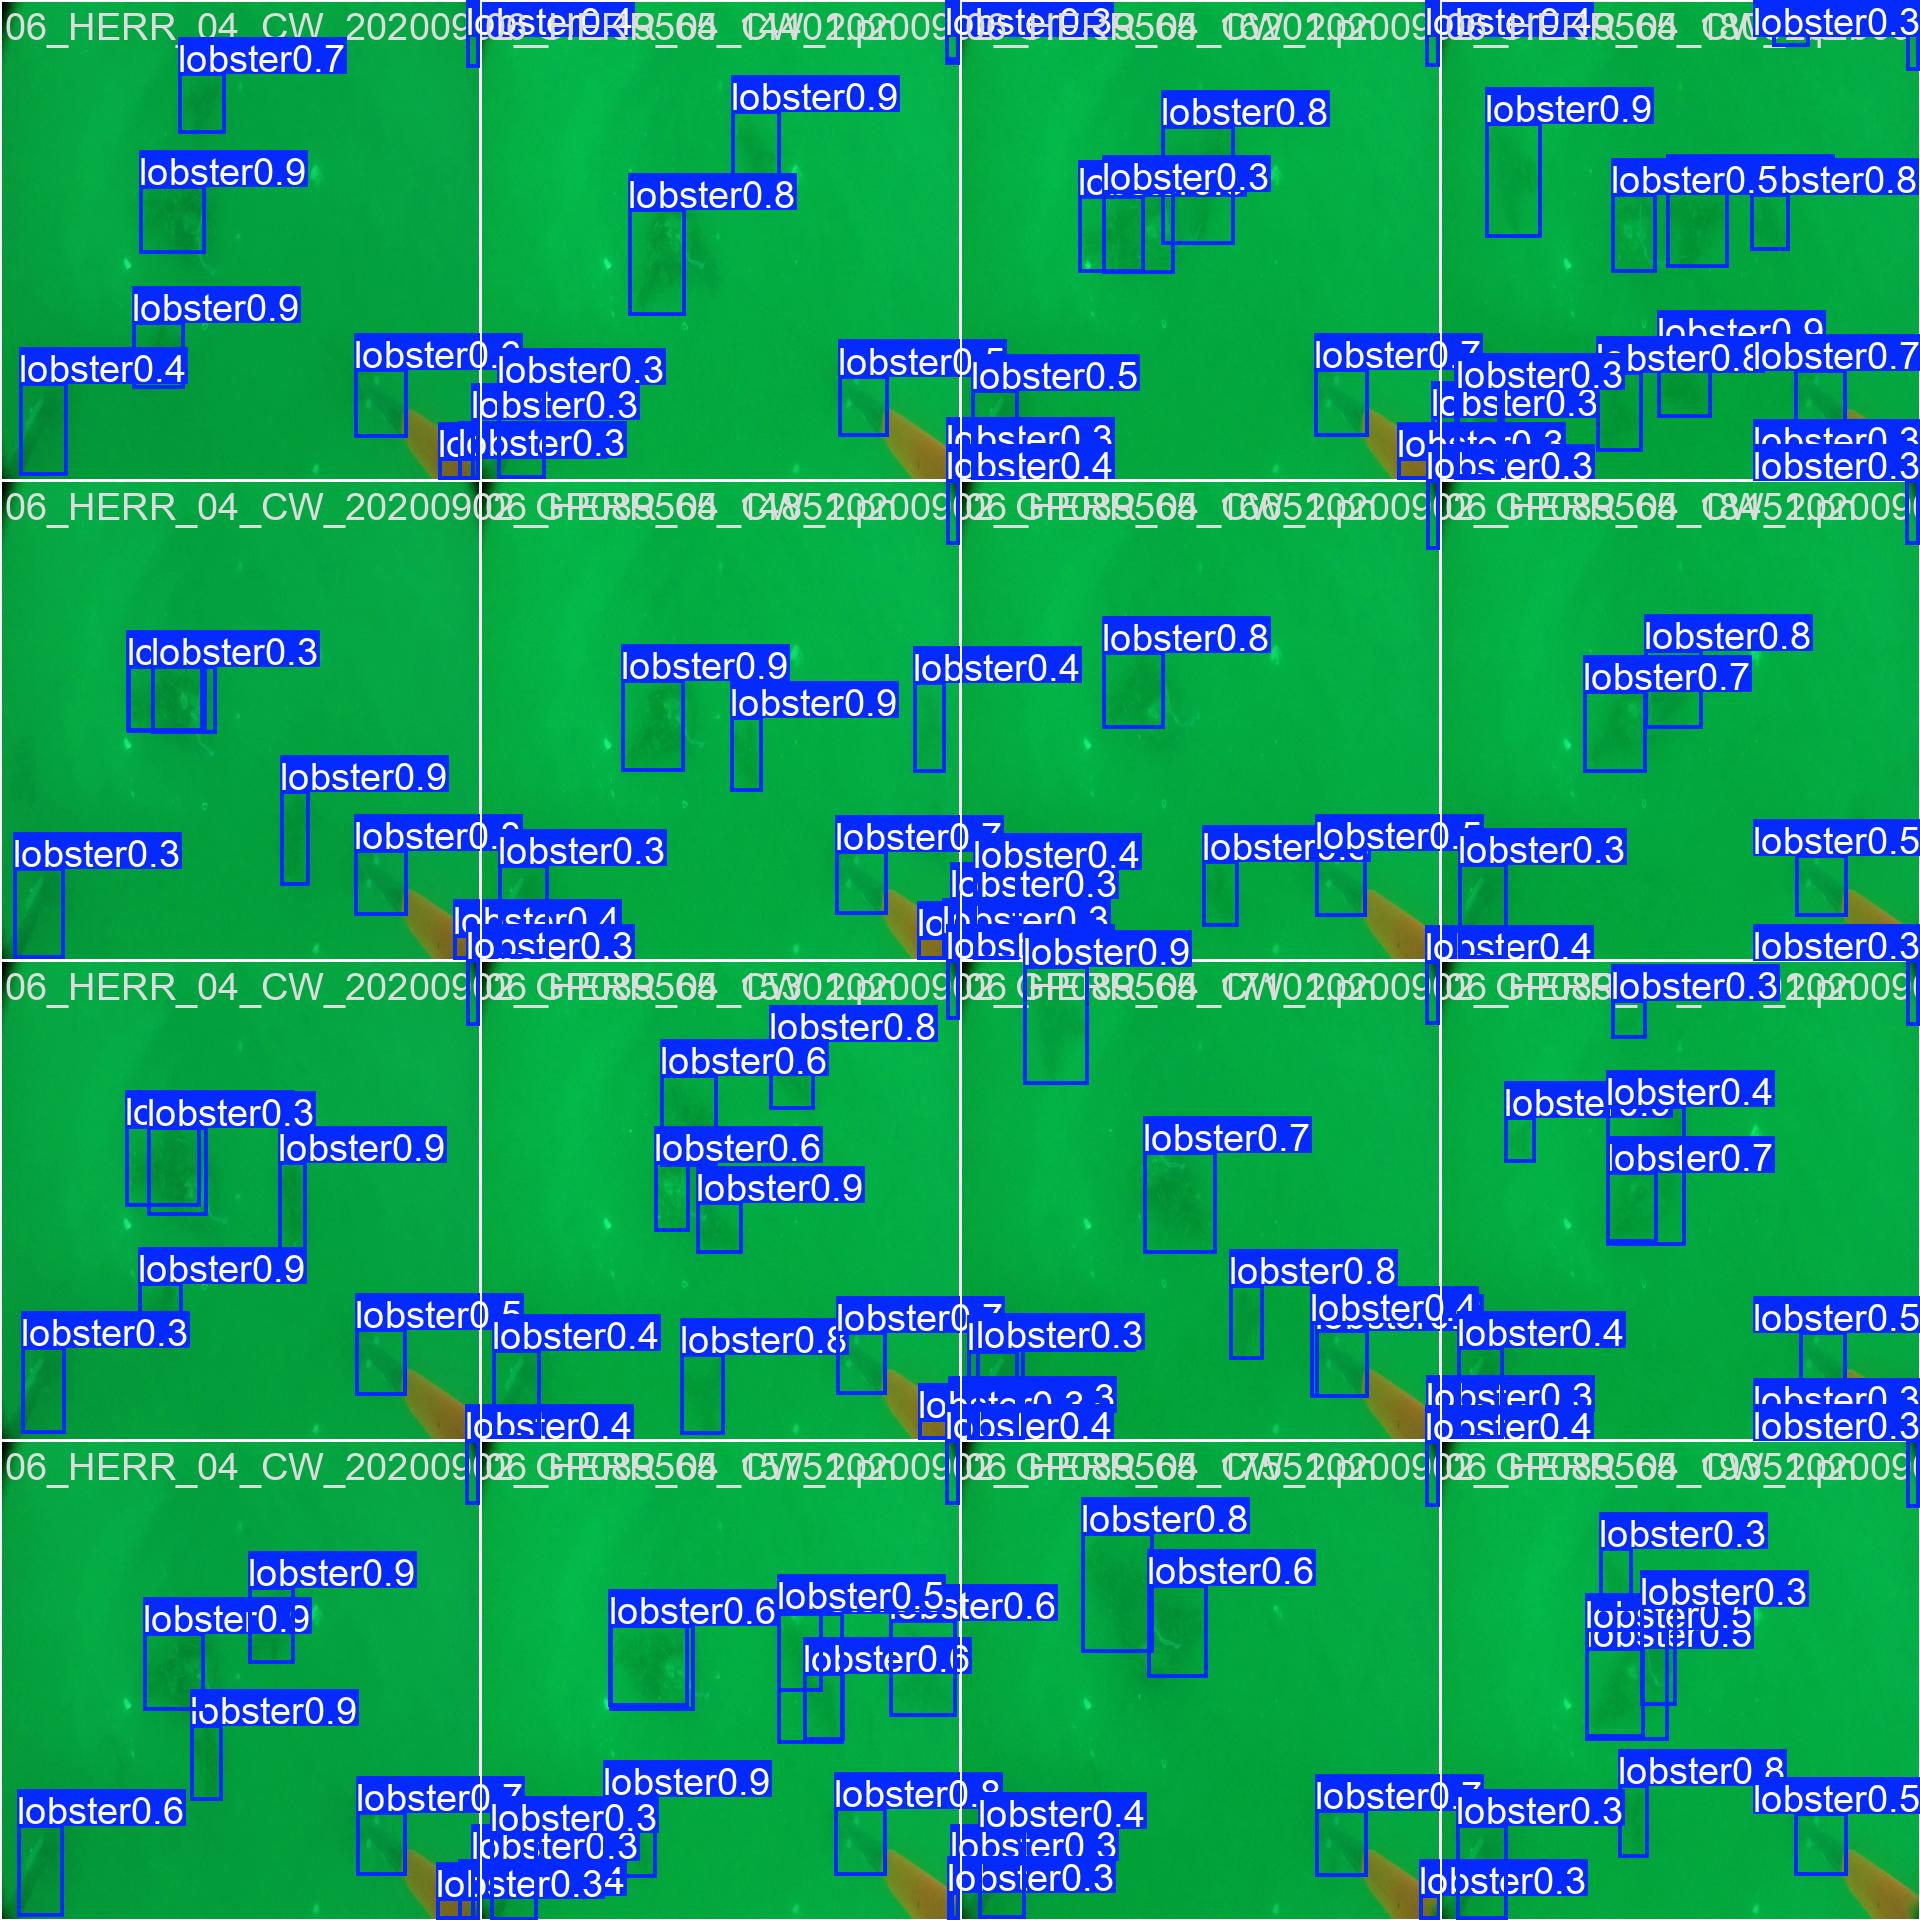

**Limitations:**
- v1 test sessions share sites (mostly also dates) with train sessions: this measures generalization to new sessions, not new sites (D-007).
- Test boxes are concentrated: 13_SHRI_12 + 21_SUB6_03 hold 1,135 of 1,512 (D-008).
- Substrate/visibility metadata is mostly missing; zExtra is excluded.
- ultralytics_reported precision/recall are at the confidence that maximizes F1 on the TEST split itself (Ultralytics convention); the operating point is at_val_conf, chosen on val.

In [19]:
# 17. FINAL TEST EVALUATION -- results and plots, read back from the run folder on Drive.
import glob
import json
from IPython.display import Image, Markdown, display

FINAL_DIR = os.path.join(RUNS_ROOT, FINAL_TEST_EXPERIMENT, "final_test")
assert os.path.isfile(os.path.join(FINAL_DIR, "final_test_record.json")), (
    f"no final_test_record.json in {FINAL_DIR} -- run cell 16 first")
rec = json.load(open(os.path.join(FINAL_DIR, "final_test_record.json"), encoding="utf-8"))
rep, op = rec["metrics"]["ultralytics_reported"], rec["metrics"]["at_val_conf"]
display(Markdown(f"# FINAL TEST EVALUATION — {rec['experiment_id']} (split = `{rec['split']}`, "
                 f"attempt {rec['attempts_including_this_one']})"))
rows = ["| metric | value |", "|---|---|",
        f"| mAP50 | {rep['map50']:.4f} |", f"| mAP50-95 | {rep['map50_95']:.4f} |"]
if op:
    rows += [f"| precision @ val-chosen conf {op['conf']:.3f} | {op['precision']:.4f} |",
             f"| recall @ val-chosen conf {op['conf']:.3f} | {op['recall']:.4f} |",
             f"| F1 @ val-chosen conf {op['conf']:.3f} | {op['f1']:.4f} |"]
rows += [f"| precision (Ultralytics: max-F1 conf on test) | {rep['precision']:.4f} |",
         f"| recall (Ultralytics: max-F1 conf on test) | {rep['recall']:.4f} |"]
display(Markdown("\n".join(rows)))
print("confusion matrix (rows = predicted, cols = true; lobster, background):",
      (rec["metrics"]["confusion_matrix"] or {}).get("matrix"))

PLOTS = [("Confusion matrix", ["confusion_matrix.png", "confusion_matrix_normalized.png"]),
         ("Precision-recall curve", ["BoxPR_curve.png", "PR_curve.png"]),
         ("F1 curve", ["BoxF1_curve.png", "F1_curve.png"])]
for title, names in PLOTS:
    found = [os.path.join(FINAL_DIR, "test", n) for n in names if os.path.isfile(os.path.join(FINAL_DIR, "test", n))]
    display(Markdown(f"### {title}" + ("" if found else " — not produced by this Ultralytics version")))
    for p in found:
        display(Image(filename=p, width=700))

display(Markdown(f"### Prediction examples at the val-chosen confidence ({op['conf']:.3f})" if op else
                 "### Prediction examples"))
for p in sorted(glob.glob(os.path.join(FINAL_DIR, "predictions", "*.*"))):
    display(Image(filename=p, width=900))
display(Markdown("### Ultralytics validation batches (labels vs predictions with confidence)"))
for p in sorted(glob.glob(os.path.join(FINAL_DIR, "test", "val_batch*_pred.jpg"))):
    display(Image(filename=p, width=900))
display(Markdown("**Limitations:**\n" + "\n".join(f"- {l}" for l in rec["limitations"])))